# Ablation study: Task-informed EEG denoising

## Цель

Проверить вклад отдельных компонентов task-informed loss
в сохранение motor-imagery информации после denoising.

В предыдущем эксперименте использовался loss:

\[
L =
L_{MSE}
+
0.1 L_{PSD}
+
0.1 L_{Cov}
\]

где:

- `MSE` — ошибка реконструкции сигнала;
- `PSD loss` — сохранение спектральной структуры EEG в диапазоне 8–30 Hz;
- `Covariance loss` — сохранение пространственных связей между EEG-каналами.

Сравниваются четыре варианта:

1. `MSE`
2. `MSE + PSD`
3. `MSE + Covariance`
4. `MSE + PSD + Covariance`

Эксперимент проводится на BCI Competition IV 2a
с полусинтетическим загрязнением EOG + EMG при SNR = -5 dB.

Для downstream-оценки используется сохранённый
Cho2017-pretrained EEGNet classifier,
fine-tuned отдельно для каждого BCI2a subject.

### Основной вопрос

Какая часть task-informed loss даёт прирост
motor-imagery classification accuracy после denoising?

## 1. Environment, paths and saved models

Новый ноутбук не зависит от предыдущих экспериментов.

Используем:

- BCI Competition IV 2a как target dataset;
- EEGdenoiseNet как источник EOG/EMG-артефактов;
- сохранённые subject-specific classifiers из предыдущего эксперимента;
- новый denoiser обучается отдельно для каждого ablation-варианта.

Для начала проверяем, что все необходимые файлы и модели доступны.

In [1]:
# ============================================================
# 1. IMPORTS, PATHS, SEED
# ============================================================

import os
import glob
import copy
import random
import warnings

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F

import mne

from scipy.io import loadmat

from torch.utils.data import (
    Dataset,
    DataLoader,
    TensorDataset
)

from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    cohen_kappa_score
)

from datasets import load_from_disk


warnings.filterwarnings("ignore")


# ============================================================
# PATHS
# ============================================================

BASE_DIR = "/Users/irina/Desktop/master project"

BCI2A_DIR = os.path.join(
    BASE_DIR,
    "BCICIV_2a_gdf"
)

BCI2A_LABELS_DIR = os.path.join(
    BASE_DIR,
    "true_labels"
)

EEGDENOISE_DIR = os.path.join(
    BASE_DIR,
    "EEGdenoiseNet_artifacts"
)

MODEL_DIR = os.path.join(
    BASE_DIR,
    "models_v2"
)

RESULTS_DIR = os.path.join(
    BASE_DIR,
    "results_v2"
)


# ============================================================
# SAVED SUBJECT-SPECIFIC CLASSIFIERS
# ============================================================

CLASSIFIER_DIR = os.path.join(
    MODEL_DIR,
    "final_transfer_aware_denoising"
)


# ============================================================
# OUTPUT FOR THIS ABLATION
# ============================================================

ABLATION_DIR = os.path.join(
    RESULTS_DIR,
    "ablation_task_informed"
)

ABLATION_MODEL_DIR = os.path.join(
    MODEL_DIR,
    "ablation_task_informed"
)

os.makedirs(
    ABLATION_DIR,
    exist_ok=True
)

os.makedirs(
    ABLATION_MODEL_DIR,
    exist_ok=True
)


ABLATION_RESULTS_PATH = os.path.join(
    ABLATION_DIR,
    "ablation_results.csv"
)


# ============================================================
# EXPERIMENT SETTINGS
# ============================================================

SFREQ = 250

TARGET_SNR_DB = -5

SEED = 42

DENOISER_BATCH_SIZE = 16

DENOISER_EPOCHS = 150

DENOISER_PATIENCE = 20

DENOISER_LR = 1e-3


# ============================================================
# LOSS WEIGHTS
# ============================================================

LAMBDA_PSD = 0.1
LAMBDA_COV = 0.1


# ============================================================
# DEVICE
# ============================================================

if torch.backends.mps.is_available():

    denoiser_device = torch.device(
        "mps"
    )

else:

    denoiser_device = torch.device(
        "cpu"
    )


classifier_device = torch.device(
    "cpu"
)


# ============================================================
# SEED
# ============================================================

def set_seed(seed=42):

    random.seed(seed)

    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():

        torch.cuda.manual_seed_all(
            seed
        )


set_seed(SEED)


print(
    "Denoiser device:",
    denoiser_device
)

print(
    "Classifier device:",
    classifier_device
)

print(
    "Ablation results:",
    ABLATION_RESULTS_PATH
)

Denoiser device: mps
Classifier device: cpu
Ablation results: /Users/irina/Desktop/master project/results_v2/ablation_task_informed/ablation_results.csv


In [2]:
# ============================================================
# 2. CHECK ALL REQUIRED FILES
# ============================================================

required_dirs = {
    "BCI2A":
        BCI2A_DIR,

    "BCI2A labels":
        BCI2A_LABELS_DIR,

    "EEGdenoiseNet":
        EEGDENOISE_DIR,

    "Saved classifiers":
        CLASSIFIER_DIR
}


all_ok = True


for name, path in required_dirs.items():

    exists = os.path.exists(
        path
    )

    print(
        f"{name:20s}",
        "OK" if exists else "MISSING",
        path
    )

    if not exists:

        all_ok = False


print(
    "\nSaved subject classifiers:"
)


for subject_num in range(
    1,
    10
):

    subject = f"A{subject_num:02d}"

    classifier_path = os.path.join(
        CLASSIFIER_DIR,
        f"{subject}_pretrained_classifier.pt"
    )

    exists = os.path.exists(
        classifier_path
    )

    print(
        subject,
        "OK" if exists else "MISSING",
        classifier_path
    )

    if not exists:

        all_ok = False


if not all_ok:

    raise RuntimeError(
        "Не все файлы найдены. "
        "Останавливаемся до обучения."
    )


print(
    "\nВСЁ НА МЕСТЕ"
)

BCI2A                OK /Users/irina/Desktop/master project/BCICIV_2a_gdf
BCI2A labels         OK /Users/irina/Desktop/master project/true_labels
EEGdenoiseNet        OK /Users/irina/Desktop/master project/EEGdenoiseNet_artifacts
Saved classifiers    OK /Users/irina/Desktop/master project/models_v2/final_transfer_aware_denoising

Saved subject classifiers:
A01 OK /Users/irina/Desktop/master project/models_v2/final_transfer_aware_denoising/A01_pretrained_classifier.pt
A02 OK /Users/irina/Desktop/master project/models_v2/final_transfer_aware_denoising/A02_pretrained_classifier.pt
A03 OK /Users/irina/Desktop/master project/models_v2/final_transfer_aware_denoising/A03_pretrained_classifier.pt
A04 OK /Users/irina/Desktop/master project/models_v2/final_transfer_aware_denoising/A04_pretrained_classifier.pt
A05 OK /Users/irina/Desktop/master project/models_v2/final_transfer_aware_denoising/A05_pretrained_classifier.pt
A06 OK /Users/irina/Desktop/master project/models_v2/final_transfer_aware_de

## 2. EEGdenoiseNet artifacts and BCI2a loading

Для искусственного загрязнения BCI2a используем реальные EOG- и EMG-компоненты
из EEGdenoiseNet.

Артефакт определяется как:

\[
artifact = contaminated - clean
\]

Затем EOG и EMG комбинируются и масштабируются до заданного SNR.

Для target dataset используется BCI Competition IV 2a:

- AxxT → train / validation;
- AxxE → independent test;
- 22 EEG-канала;
- фильтрация 0.5–100 Hz;
- 250 Hz;
- эпоха 0–3.996 s.

Загружаем EEGdenoiseNet

In [3]:
# ============================================================
# 3. LOAD EEGDENOISENET
# ============================================================

EOG_train = load_from_disk(
    os.path.join(
        EEGDENOISE_DIR,
        "EEGDenoiseNet_EOG",
        "train"
    )
)

EMG_train = load_from_disk(
    os.path.join(
        EEGDENOISE_DIR,
        "EEGDenoiseNet_EMG",
        "train"
    )
)

print(
    "EOG samples:",
    len(EOG_train)
)

print(
    "EMG samples:",
    len(EMG_train)
)

EOG samples: 27180
EMG samples: 44930


Функции для артефактов

In [4]:
# ============================================================
# 4. EEGDENOISENET ARTIFACT HELPERS
# ============================================================

EOG_CHANNEL_WEIGHTS = np.array(
    [
        1.00,
        0.85, 0.90, 0.95, 0.90, 0.85,
        0.65, 0.70, 0.75, 0.80, 0.75, 0.70, 0.65,
        0.45, 0.50, 0.55, 0.50, 0.45,
        0.30, 0.35, 0.30,
        0.20
    ],
    dtype=np.float32
)


def extract_artifact(
    dataset,
    idx
):
    row = dataset[
        int(idx) % len(dataset)
    ]

    clean = np.asarray(
        row["x"],
        dtype=np.float32
    )

    contaminated = np.asarray(
        row["y"],
        dtype=np.float32
    )

    artifact = contaminated - clean

    artifact = (
        artifact
        - artifact.mean()
    )

    return artifact.astype(
        np.float32
    )


def make_artifact_signal(
    dataset,
    target_length,
    rng
):
    pieces = []
    total_length = 0

    while total_length < target_length:

        idx = rng.integers(
            0,
            len(dataset)
        )

        piece = extract_artifact(
            dataset,
            idx
        )

        pieces.append(
            piece
        )

        total_length += len(
            piece
        )

    signal = np.concatenate(
        pieces
    )[:target_length]

    signal = (
        signal
        - signal.mean()
    )

    return signal.astype(
        np.float32
    )


def make_multichannel_eog(
    target_length,
    rng
):
    base = make_artifact_signal(
        EOG_train,
        target_length,
        rng
    )

    artifact = (
        EOG_CHANNEL_WEIGHTS[:, None]
        * base[None, :]
    )

    return artifact.astype(
        np.float32
    )


def make_multichannel_emg(
    target_length,
    rng
):
    base = make_artifact_signal(
        EMG_train,
        target_length,
        rng
    )

    channel_weights = rng.uniform(
        0.4,
        1.0,
        size=22
    ).astype(
        np.float32
    )

    artifact = (
        channel_weights[:, None]
        * base[None, :]
    )

    return artifact.astype(
        np.float32
    )


def make_mixed_artifact(
    target_length,
    rng
):
    eog = make_multichannel_eog(
        target_length,
        rng
    )

    emg = make_multichannel_emg(
        target_length,
        rng
    )

    artifact = (
        0.5 * eog
        +
        0.5 * emg
    )

    artifact = (
        artifact
        - artifact.mean()
    )

    return artifact.astype(
        np.float32
    )


def add_artifact_at_snr(
    clean,
    artifact,
    snr_db
):
    signal_power = np.mean(
        clean ** 2
    )

    artifact_power = (
        np.mean(
            artifact ** 2
        )
        + 1e-20
    )

    target_noise_power = (
        signal_power
        /
        (
            10 ** (
                snr_db / 10
            )
        )
    )

    scale = np.sqrt(
        target_noise_power
        / artifact_power
    )

    scaled_artifact = (
        artifact
        * scale
    )

    noisy = (
        clean
        + scaled_artifact
    )

    return (
        noisy.astype(
            np.float32
        ),
        scaled_artifact.astype(
            np.float32
        )
    )

Loader для BCI Competition IV 2a

In [5]:
# ============================================================
# 5. BCI2A LOADING
# ============================================================

BCI2A_EVENT_ID = {
    "769": 0,  # left hand
    "770": 1,  # right hand
    "771": 2,  # feet
    "772": 3   # tongue
}


def load_bci2a_train(
    gdf_file
):
    raw = mne.io.read_raw_gdf(
        gdf_file,
        preload=True,
        verbose=False
    )

    # первые 22 канала — EEG
    raw.pick(
        raw.ch_names[:22]
    )

    raw.filter(
        l_freq=0.5,
        h_freq=100.0,
        verbose=False
    )

    events, event_id = (
        mne.events_from_annotations(
            raw,
            verbose=False
        )
    )

    reverse_event_id = {
        value: key
        for key, value
        in event_id.items()
    }

    selected_events = []
    labels = []

    for event in events:

        annotation = (
            reverse_event_id.get(
                event[2]
            )
        )

        if annotation in BCI2A_EVENT_ID:

            selected_events.append(
                event.copy()
            )

            labels.append(
                BCI2A_EVENT_ID[
                    annotation
                ]
            )

    selected_events = np.asarray(
        selected_events
    )

    y = np.asarray(
        labels,
        dtype=np.int64
    )

    selected_events[:, 2] = 1

    epochs = mne.Epochs(
        raw,
        selected_events,
        event_id={
            "trial": 1
        },
        tmin=0.0,
        tmax=3.996,
        baseline=None,
        preload=True,
        verbose=False
    )

    X = epochs.get_data(
        copy=True
    ).astype(
        np.float32
    )

    return X, y


def load_bci2a_test(
    gdf_file,
    labels_file
):
    raw = mne.io.read_raw_gdf(
        gdf_file,
        preload=True,
        verbose=False
    )

    raw.pick(
        raw.ch_names[:22]
    )

    raw.filter(
        l_freq=0.5,
        h_freq=100.0,
        verbose=False
    )

    events, event_id = (
        mne.events_from_annotations(
            raw,
            verbose=False
        )
    )

    if "783" not in event_id:

        raise ValueError(
            f"Event 783 not found: {event_id}"
        )

    cue_events = events[
        events[:, 2]
        == event_id["783"]
    ].copy()

    cue_events[:, 2] = 1

    epochs = mne.Epochs(
        raw,
        cue_events,
        event_id={
            "trial": 1
        },
        tmin=0.0,
        tmax=3.996,
        baseline=None,
        preload=True,
        verbose=False
    )

    X = epochs.get_data(
        copy=True
    ).astype(
        np.float32
    )

    labels_mat = loadmat(
        labels_file
    )

    y = (
        labels_mat[
            "classlabel"
        ]
        .squeeze()
        .astype(
            np.int64
        )
        - 1
    )

    if len(X) != len(y):

        raise ValueError(
            f"X/y mismatch: "
            f"{len(X)} vs {len(y)}"
        )

    return X, y


def prepare_subject_for_ablation(
    subject_num,
    val_size=0.2,
    random_state=42
):
    subject = (
        f"A{subject_num:02d}"
    )

    train_file = os.path.join(
        BCI2A_DIR,
        f"{subject}T.gdf"
    )

    eval_file = os.path.join(
        BCI2A_DIR,
        f"{subject}E.gdf"
    )

    labels_file = os.path.join(
        BCI2A_LABELS_DIR,
        f"{subject}E.mat"
    )

    X_all, y_all = (
        load_bci2a_train(
            train_file
        )
    )

    X_test, y_test = (
        load_bci2a_test(
            eval_file,
            labels_file
        )
    )

    (
        X_train,
        X_val,
        y_train,
        y_val
    ) = train_test_split(
        X_all,
        y_all,
        test_size=val_size,
        random_state=random_state,
        stratify=y_all
    )

    return (
        X_train.astype(
            np.float32
        ),
        X_val.astype(
            np.float32
        ),
        X_test.astype(
            np.float32
        ),
        y_train.astype(
            np.int64
        ),
        y_val.astype(
            np.int64
        ),
        y_test.astype(
            np.int64
        )
    )

Проверяем всё на A01

In [6]:
# ============================================================
# 6. SANITY CHECK ON A01
# ============================================================

(
    X_train_a01,
    X_val_a01,
    X_test_a01,
    y_train_a01,
    y_val_a01,
    y_test_a01
) = prepare_subject_for_ablation(
    1
)

print(
    "Train:",
    X_train_a01.shape
)

print(
    "Val:",
    X_val_a01.shape
)

print(
    "Test:",
    X_test_a01.shape
)

print(
    "\nTrain classes:",
    np.unique(
        y_train_a01,
        return_counts=True
    )
)

print(
    "Test classes:",
    np.unique(
        y_test_a01,
        return_counts=True
    )
)

Train: (230, 22, 1000)
Val: (58, 22, 1000)
Test: (288, 22, 1000)

Train classes: (array([0, 1, 2, 3]), array([57, 58, 57, 58]))
Test classes: (array([0, 1, 2, 3]), array([72, 72, 72, 72]))


Теперь проверим саму полусинтетику на одном trial:

In [7]:
rng = np.random.default_rng(
    42
)

clean = X_test_a01[0]

artifact = make_mixed_artifact(
    clean.shape[-1],
    rng
)

noisy, scaled_artifact = (
    add_artifact_at_snr(
        clean,
        artifact,
        snr_db=-5
    )
)


def actual_snr_db(
    clean,
    noisy
):
    noise = (
        noisy
        - clean
    )

    return (
        10
        * np.log10(
            np.mean(
                clean ** 2
            )
            /
            (
                np.mean(
                    noise ** 2
                )
                + 1e-20
            )
        )
    )


print(
    "Clean shape:",
    clean.shape
)

print(
    "Noisy shape:",
    noisy.shape
)

print(
    "Actual SNR:",
    round(
        actual_snr_db(
            clean,
            noisy
        ),
        3
    ),
    "dB"
)

Clean shape: (22, 1000)
Noisy shape: (22, 1000)
Actual SNR: -5.0 dB


## 3. Ablation variants of task-informed loss

Для всех вариантов используется одна и та же архитектура denoiser.

Меняется только функция потерь:

1. `MSE`
2. `MSE + PSD`
3. `MSE + Covariance`
4. `MSE + PSD + Covariance`

Это позволяет отдельно оценить вклад спектрального ограничения
и пространственной covariance-компоненты.


In [8]:
# ============================================================
# 7. DENOISING DATASET
# ============================================================

class BCIDenoisingDataset(Dataset):

    def __init__(
        self,
        X_clean,
        snr_min=-5,
        snr_max=5,
        deterministic=False,
        seed=42
    ):
        self.X_clean = np.asarray(
            X_clean,
            dtype=np.float32
        )

        self.snr_min = snr_min
        self.snr_max = snr_max

        self.deterministic = deterministic
        self.seed = seed


    def __len__(self):
        return len(self.X_clean)


    def __getitem__(self, idx):

        clean = self.X_clean[idx].copy()

        if self.deterministic:
            rng = np.random.default_rng(
                self.seed + idx
            )
        else:
            rng = np.random.default_rng()

        snr_db = rng.uniform(
            self.snr_min,
            self.snr_max
        )

        artifact = make_mixed_artifact(
            clean.shape[-1],
            rng
        )

        noisy, _ = add_artifact_at_snr(
            clean,
            artifact,
            snr_db
        )

        # Важно:
        # нормализуем только по noisy,
        # чтобы не использовать clean на inference
        scale = (
            noisy.std()
            + 1e-8
        )

        noisy_norm = (
            noisy / scale
        ).astype(np.float32)

        clean_norm = (
            clean / scale
        ).astype(np.float32)

        return (
            torch.tensor(
                noisy_norm,
                dtype=torch.float32
            ),
            torch.tensor(
                clean_norm,
                dtype=torch.float32
            )
        )

In [9]:
# ============================================================
# 8. MULTICHANNEL RESIDUAL DENOISER
# ============================================================

class MultichannelResidualDenoiser(nn.Module):

    def __init__(
        self,
        n_channels=22,
        hidden=64
    ):
        super().__init__()

        self.net = nn.Sequential(

            nn.Conv1d(
                n_channels,
                hidden,
                kernel_size=9,
                padding=4
            ),
            nn.BatchNorm1d(hidden),
            nn.GELU(),

            nn.Conv1d(
                hidden,
                hidden,
                kernel_size=7,
                padding=3
            ),
            nn.BatchNorm1d(hidden),
            nn.GELU(),

            nn.Conv1d(
                hidden,
                hidden,
                kernel_size=5,
                padding=2
            ),
            nn.BatchNorm1d(hidden),
            nn.GELU(),

            nn.Conv1d(
                hidden,
                hidden,
                kernel_size=5,
                padding=2
            ),
            nn.BatchNorm1d(hidden),
            nn.GELU(),

            nn.Conv1d(
                hidden,
                32,
                kernel_size=3,
                padding=1
            ),
            nn.GELU(),

            nn.Conv1d(
                32,
                n_channels,
                kernel_size=3,
                padding=1
            )
        )


    def forward(self, noisy):

        predicted_noise = self.net(
            noisy
        )

        return (
            noisy
            - predicted_noise
        )

In [10]:
# ============================================================
# 9. LOSS COMPONENTS
# ============================================================

def mse_loss(
    pred,
    target
):
    return F.mse_loss(
        pred,
        target
    )


def spectral_loss(
    pred,
    target,
    sfreq=250,
    fmin=8,
    fmax=30
):
    pred_fft = torch.fft.rfft(
        pred,
        dim=-1
    )

    target_fft = torch.fft.rfft(
        target,
        dim=-1
    )

    pred_power = (
        torch.abs(pred_fft) ** 2
    )

    target_power = (
        torch.abs(target_fft) ** 2
    )

    freqs = torch.fft.rfftfreq(
        pred.shape[-1],
        d=1.0 / sfreq,
        device=pred.device
    )

    mask = (
        (freqs >= fmin)
        &
        (freqs <= fmax)
    )

    return F.mse_loss(
        torch.log1p(
            pred_power[..., mask]
        ),
        torch.log1p(
            target_power[..., mask]
        )
    )


def covariance_loss(
    pred,
    target
):
    pred_centered = (
        pred
        - pred.mean(
            dim=-1,
            keepdim=True
        )
    )

    target_centered = (
        target
        - target.mean(
            dim=-1,
            keepdim=True
        )
    )

    T = pred.shape[-1]

    pred_cov = (
        pred_centered
        @ pred_centered.transpose(
            1,
            2
        )
    ) / (T - 1)

    target_cov = (
        target_centered
        @ target_centered.transpose(
            1,
            2
        )
    ) / (T - 1)

    return F.mse_loss(
        pred_cov,
        target_cov
    )

In [11]:
# ============================================================
# 10. ABLATION LOSS
# ============================================================

def ablation_loss(
    pred,
    target,
    variant,
    lambda_psd=0.1,
    lambda_cov=0.1
):
    loss_mse = mse_loss(
        pred,
        target
    )

    loss_psd = torch.tensor(
        0.0,
        device=pred.device
    )

    loss_cov = torch.tensor(
        0.0,
        device=pred.device
    )


    if variant in [
        "MSE_PSD",
        "FULL"
    ]:
        loss_psd = spectral_loss(
            pred,
            target,
            sfreq=SFREQ,
            fmin=8,
            fmax=30
        )


    if variant in [
        "MSE_COV",
        "FULL"
    ]:
        loss_cov = covariance_loss(
            pred,
            target
        )


    total = (
        loss_mse
        +
        lambda_psd * loss_psd
        +
        lambda_cov * loss_cov
    )


    return (
        total,
        loss_mse,
        loss_psd,
        loss_cov
    )

In [12]:
ABLATION_VARIANTS = [
    "MSE",
    "MSE_PSD",
    "MSE_COV",
    "FULL"
]

print(
    ABLATION_VARIANTS
)

['MSE', 'MSE_PSD', 'MSE_COV', 'FULL']


In [13]:
# ============================================================
# 11. LOSS SANITY CHECK
# ============================================================

test_model = (
    MultichannelResidualDenoiser(
        n_channels=22
    )
    .to(
        denoiser_device
    )
)

train_ds_test = BCIDenoisingDataset(
    X_train_a01,
    snr_min=-5,
    snr_max=5,
    deterministic=True,
    seed=42
)

noisy_test, clean_test = (
    train_ds_test[0]
)

noisy_test = (
    noisy_test
    .unsqueeze(0)
    .to(
        denoiser_device
    )
)

clean_test = (
    clean_test
    .unsqueeze(0)
    .to(
        denoiser_device
    )
)

with torch.no_grad():

    pred_test = test_model(
        noisy_test
    )


for variant in ABLATION_VARIANTS:

    (
        total,
        lmse,
        lpsd,
        lcov
    ) = ablation_loss(
        pred_test,
        clean_test,
        variant=variant,
        lambda_psd=LAMBDA_PSD,
        lambda_cov=LAMBDA_COV
    )

    print(
        f"{variant:10s} | "
        f"total={total.item():.4f} | "
        f"MSE={lmse.item():.4f} | "
        f"PSD={lpsd.item():.4f} | "
        f"COV={lcov.item():.4f}"
    )

MSE        | total=0.3309 | MSE=0.3309 | PSD=0.0000 | COV=0.0000
MSE_PSD    | total=0.4144 | MSE=0.3309 | PSD=0.8350 | COV=0.0000
MSE_COV    | total=0.3479 | MSE=0.3309 | PSD=0.0000 | COV=0.1708
FULL       | total=0.4314 | MSE=0.3309 | PSD=0.8350 | COV=0.1708


## 4. Training one ablation variant

Для каждого варианта loss обучается одинаковая архитектура denoiser
на одинаковом train/validation split.

Меняется только состав функции потерь.

Используем early stopping по validation loss.

In [15]:
# ============================================================
# 12. TRAIN ONE ABLATION DENOISER
# ============================================================

def train_ablation_denoiser(
    X_train,
    X_val,
    variant,
    subject="A01",
    epochs=DENOISER_EPOCHS,
    batch_size=DENOISER_BATCH_SIZE,
    lr=DENOISER_LR,
    patience=DENOISER_PATIENCE,
    seed=42
):
    set_seed(seed)

    train_ds = BCIDenoisingDataset(
        X_train,
        snr_min=-5,
        snr_max=5,
        deterministic=False,
        seed=seed
    )

    val_ds = BCIDenoisingDataset(
        X_val,
        snr_min=-5,
        snr_max=5,
        deterministic=True,
        seed=seed + 10_000
    )

    train_loader = DataLoader(
        train_ds,
        batch_size=batch_size,
        shuffle=True,
        num_workers=0
    )

    val_loader = DataLoader(
        val_ds,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0
    )

    model = MultichannelResidualDenoiser(
        n_channels=22,
        hidden=64
    ).to(denoiser_device)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=lr
    )

    best_val_loss = np.inf
    best_state = None
    bad_epochs = 0

    history = []

    for epoch in range(1, epochs + 1):

        # -------------------------
        # TRAIN
        # -------------------------

        model.train()

        train_total = 0.0
        train_mse = 0.0
        train_psd = 0.0
        train_cov = 0.0

        n_train = 0

        for noisy, clean in train_loader:

            noisy = noisy.to(
                denoiser_device
            )

            clean = clean.to(
                denoiser_device
            )

            optimizer.zero_grad()

            pred = model(
                noisy
            )

            (
                loss,
                loss_mse,
                loss_psd,
                loss_cov
            ) = ablation_loss(
                pred,
                clean,
                variant=variant,
                lambda_psd=LAMBDA_PSD,
                lambda_cov=LAMBDA_COV
            )

            loss.backward()

            optimizer.step()

            bs = noisy.shape[0]

            train_total += (
                loss.item() * bs
            )

            train_mse += (
                loss_mse.item() * bs
            )

            train_psd += (
                loss_psd.item() * bs
            )

            train_cov += (
                loss_cov.item() * bs
            )

            n_train += bs

        train_total /= n_train
        train_mse /= n_train
        train_psd /= n_train
        train_cov /= n_train

        # -------------------------
        # VALIDATION
        # -------------------------

        model.eval()

        val_total = 0.0
        val_mse = 0.0
        val_psd = 0.0
        val_cov = 0.0

        n_val = 0

        with torch.no_grad():

            for noisy, clean in val_loader:

                noisy = noisy.to(
                    denoiser_device
                )

                clean = clean.to(
                    denoiser_device
                )

                pred = model(
                    noisy
                )

                (
                    loss,
                    loss_mse,
                    loss_psd,
                    loss_cov
                ) = ablation_loss(
                    pred,
                    clean,
                    variant=variant,
                    lambda_psd=LAMBDA_PSD,
                    lambda_cov=LAMBDA_COV
                )

                bs = noisy.shape[0]

                val_total += (
                    loss.item() * bs
                )

                val_mse += (
                    loss_mse.item() * bs
                )

                val_psd += (
                    loss_psd.item() * bs
                )

                val_cov += (
                    loss_cov.item() * bs
                )

                n_val += bs

        val_total /= n_val
        val_mse /= n_val
        val_psd /= n_val
        val_cov /= n_val

        history.append({
            "epoch": epoch,

            "train_loss":
                train_total,

            "train_mse":
                train_mse,

            "train_psd":
                train_psd,

            "train_cov":
                train_cov,

            "val_loss":
                val_total,

            "val_mse":
                val_mse,

            "val_psd":
                val_psd,

            "val_cov":
                val_cov
        })

        # -------------------------
        # EARLY STOPPING
        # -------------------------

        if val_total < best_val_loss:

            best_val_loss = val_total

            best_state = copy.deepcopy(
                model.state_dict()
            )

            bad_epochs = 0

        else:

            bad_epochs += 1

        if (
            epoch == 1
            or epoch % 10 == 0
            or bad_epochs == patience
        ):

            print(
                f"{subject} | "
                f"{variant:8s} | "
                f"epoch {epoch:3d} | "
                f"train={train_total:.4f} | "
                f"val={val_total:.4f}"
            )

        if bad_epochs >= patience:

            print(
                f"{subject} | "
                f"{variant} | "
                f"early stopping at epoch {epoch}"
            )

            break

    model.load_state_dict(
        best_state
    )

    history_df = pd.DataFrame(
        history
    )

    return (
        model,
        history_df,
        best_val_loss
    )

In [16]:
# ============================================================
# 13. TRAIN ALL 4 VARIANTS ON A01
# ============================================================

A01_MODELS = {}

A01_HISTORIES = {}

A01_BEST_VAL = {}


for variant in ABLATION_VARIANTS:

    print(
        "\n" + "=" * 70
    )

    print(
        "Training:",
        variant
    )

    print(
        "=" * 70
    )

    model, history_df, best_val = (
        train_ablation_denoiser(
            X_train=X_train_a01,
            X_val=X_val_a01,
            variant=variant,
            subject="A01",
            seed=42
        )
    )

    A01_MODELS[variant] = model

    A01_HISTORIES[variant] = (
        history_df
    )

    A01_BEST_VAL[variant] = (
        best_val
    )

    model_path = os.path.join(
        ABLATION_MODEL_DIR,
        f"A01_{variant}.pt"
    )

    history_path = os.path.join(
        ABLATION_DIR,
        f"A01_{variant}_history.csv"
    )

    torch.save(
        model.state_dict(),
        model_path
    )

    history_df.to_csv(
        history_path,
        index=False
    )

    print(
        "Saved model:",
        model_path
    )

    print(
        "Best val loss:",
        round(
            best_val,
            6
        )
    )


Training: MSE
A01 | MSE      | epoch   1 | train=0.3480 | val=0.2979
A01 | MSE      | epoch  10 | train=0.1247 | val=0.1298
A01 | MSE      | epoch  20 | train=0.1245 | val=0.1268
A01 | MSE      | epoch  30 | train=0.1175 | val=0.1220
A01 | MSE      | epoch  40 | train=0.1169 | val=0.1244
A01 | MSE      | epoch  50 | train=0.1132 | val=0.1203
A01 | MSE      | epoch  60 | train=0.1164 | val=0.1282
A01 | MSE      | epoch  70 | train=0.1108 | val=0.1182
A01 | MSE      | epoch  80 | train=0.1080 | val=0.1198
A01 | MSE      | epoch  88 | train=0.1146 | val=0.1219
A01 | MSE | early stopping at epoch 88
Saved model: /Users/irina/Desktop/master project/models_v2/ablation_task_informed/A01_MSE.pt
Best val loss: 0.115782

Training: MSE_PSD
A01 | MSE_PSD  | epoch   1 | train=0.4779 | val=0.4205
A01 | MSE_PSD  | epoch  10 | train=0.2272 | val=0.2292
A01 | MSE_PSD  | epoch  20 | train=0.2230 | val=0.2253
A01 | MSE_PSD  | epoch  30 | train=0.2266 | val=0.2283
A01 | MSE_PSD  | epoch  40 | train=0.214

In [17]:
# ============================================================
# 14. CHECK A01 TRAINING RESULT
# ============================================================

summary_a01 = pd.DataFrame(
    {
        "variant":
            list(
                A01_BEST_VAL.keys()
            ),

        "best_val_loss":
            list(
                A01_BEST_VAL.values()
            )
    }
)

summary_a01

,variant,best_val_loss
0,MSE,0.115782
1,MSE_PSD,0.204155
2,MSE_COV,0.119881
3,FULL,0.218299


In [18]:
for variant in ABLATION_VARIANTS:

    hist = A01_HISTORIES[
        variant
    ]

    print(
        f"{variant:8s} | "
        f"epochs={len(hist):3d} | "
        f"best val="
        f"{hist['val_loss'].min():.4f}"
    )

MSE      | epochs= 88 | best val=0.1158
MSE_PSD  | epochs=150 | best val=0.2042
MSE_COV  | epochs= 50 | best val=0.1199
FULL     | epochs= 80 | best val=0.2183


In [19]:
# ============================================================
# 15. FIXED A01 TEST SET AT -5 dB
# ============================================================

def make_fixed_noisy_dataset(
    X_clean,
    snr_db=-5,
    seed=12345
):
    X_clean = np.asarray(
        X_clean,
        dtype=np.float32
    )

    X_noisy = []
    X_noise = []

    for idx, clean in enumerate(X_clean):

        rng = np.random.default_rng(
            seed + idx
        )

        artifact = make_mixed_artifact(
            clean.shape[-1],
            rng
        )

        noisy, scaled_artifact = add_artifact_at_snr(
            clean,
            artifact,
            snr_db
        )

        X_noisy.append(
            noisy
        )

        X_noise.append(
            scaled_artifact
        )

    return (
        np.stack(X_noisy).astype(np.float32),
        np.stack(X_noise).astype(np.float32)
    )


X_test_a01_noisy, X_test_a01_noise = (
    make_fixed_noisy_dataset(
        X_test_a01,
        snr_db=-5,
        seed=12345
    )
)


def dataset_snr_db(
    clean,
    noisy
):
    noise = noisy - clean

    signal_power = np.mean(
        clean ** 2,
        axis=(1, 2)
    )

    noise_power = np.mean(
        noise ** 2,
        axis=(1, 2)
    )

    snr = 10 * np.log10(
        signal_power
        /
        (noise_power + 1e-20)
    )

    return snr


snr_check = dataset_snr_db(
    X_test_a01,
    X_test_a01_noisy
)

print(
    "Mean test SNR:",
    round(
        snr_check.mean(),
        4
    ),
    "dB"
)

print(
    "Min / Max:",
    round(
        snr_check.min(),
        4
    ),
    "/",
    round(
        snr_check.max(),
        4
    )
)

Mean test SNR: -5.0 dB
Min / Max: -5.0 / -5.0


In [20]:
# ============================================================
# 16. DENOISE FIXED A01 TEST SET + RECONSTRUCTION METRICS
# ============================================================

def apply_denoiser_to_dataset(
    model,
    X_noisy,
    batch_size=32
):
    model.eval()

    outputs = []

    for start in range(
        0,
        len(X_noisy),
        batch_size
    ):
        batch = X_noisy[
            start:start + batch_size
        ].astype(np.float32)

        # та же нормализация, что и при обучении
        scales = (
            batch.std(
                axis=(1, 2),
                keepdims=True
            )
            + 1e-8
        )

        batch_norm = (
            batch / scales
        )

        batch_tensor = torch.tensor(
            batch_norm,
            dtype=torch.float32,
            device=denoiser_device
        )

        with torch.no_grad():

            denoised_norm = model(
                batch_tensor
            )

        denoised = (
            denoised_norm
            .cpu()
            .numpy()
            * scales
        )

        outputs.append(
            denoised.astype(
                np.float32
            )
        )

    return np.concatenate(
        outputs,
        axis=0
    )


def reconstruction_metrics(
    clean,
    restored
):
    error = restored - clean

    rmse = np.sqrt(
        np.mean(
            error ** 2
        )
    )

    mae = np.mean(
        np.abs(
            error
        )
    )

    signal_power = np.mean(
        clean ** 2,
        axis=(1, 2)
    )

    error_power = np.mean(
        error ** 2,
        axis=(1, 2)
    )

    snr = 10 * np.log10(
        signal_power
        /
        (
            error_power
            + 1e-20
        )
    )

    return {
        "RMSE": rmse,
        "MAE": mae,
        "SNR_dB": snr.mean()
    }


A01_RESTORED = {
    "RAW": X_test_a01_noisy
}


for variant in ABLATION_VARIANTS:

    print(
        "Denoising:",
        variant
    )

    A01_RESTORED[
        variant
    ] = apply_denoiser_to_dataset(
        A01_MODELS[variant],
        X_test_a01_noisy
    )


reconstruction_rows = []


for method, X_restored in A01_RESTORED.items():

    metrics = reconstruction_metrics(
        X_test_a01,
        X_restored
    )

    reconstruction_rows.append({
        "method": method,
        **metrics
    })


a01_reconstruction_df = (
    pd.DataFrame(
        reconstruction_rows
    )
)

a01_reconstruction_df

Denoising: MSE
Denoising: MSE_PSD
Denoising: MSE_COV
Denoising: FULL


,method,RMSE,MAE,SNR_dB
0,RAW,0.000018,0.000013,-5.000000
1,MSE,0.000007,0.000005,3.375419
2,MSE_PSD,0.000007,0.000005,3.626948
3,MSE_COV,0.000007,0.000005,3.140103
4,FULL,0.000007,0.000005,3.085925


In [21]:
import os
import glob

classifier_files = sorted(
    glob.glob(
        os.path.join(
            CLASSIFIER_DIR,
            "*A01*.pt"
        )
    )
)

for path in classifier_files:
    print(os.path.basename(path))

A01_pretrained_classifier.pt
A01_pretrained_task.pt
A01_scratch_classifier.pt
A01_scratch_mse.pt
A01_scratch_task.pt


Архитектура сохранённого EEGNet

In [22]:

# ============================================================
# 17. UNIFIED EEGNET — EXACT SAVED ARCHITECTURE
# ============================================================

class UnifiedEEGNet(nn.Module):

    def __init__(
        self,
        n_channels=22,
        n_classes=2
    ):
        super().__init__()

        self.conv1 = nn.Conv2d(
            1, 8,
            kernel_size=(1, 64),
            padding=(0, 31),
            bias=False
        )

        self.bn1 = nn.BatchNorm2d(8)

        self.depthwise = nn.Conv2d(
            8, 16,
            kernel_size=(n_channels, 1),
            groups=8,
            bias=False
        )

        self.bn2 = nn.BatchNorm2d(16)

        self.pool1 = nn.AvgPool2d(
            (1, 4)
        )

        self.drop1 = nn.Dropout(0.35)

        self.conv2 = nn.Conv2d(
            16, 32,
            kernel_size=(1, 16),
            padding=(0, 7),
            bias=False
        )

        self.bn3 = nn.BatchNorm2d(32)

        self.pool2 = nn.AvgPool2d(
            (1, 8)
        )

        self.drop2 = nn.Dropout(0.35)

        self.conv3 = nn.Conv2d(
            32, 32,
            kernel_size=(1, 8),
            padding=(0, 3),
            bias=False
        )

        self.bn4 = nn.BatchNorm2d(32)

        self.pool3 = nn.AvgPool2d(
            (1, 4)
        )

        self.drop3 = nn.Dropout(0.35)

        self.adaptive_pool = nn.AdaptiveAvgPool2d(
            (1, 8)
        )

        self.fc = nn.Sequential(
            nn.Linear(32 * 8, 64),
            nn.GELU(),
            nn.Dropout(0.5),
            nn.Linear(64, n_classes)
        )


    def forward(self, x):

        if x.ndim == 3:
            x = x.unsqueeze(1)

        x = self.conv1(x)
        x = self.bn1(x)

        x = self.depthwise(x)
        x = self.bn2(x)
        x = F.elu(x)

        x = self.pool1(x)
        x = self.drop1(x)

        x = self.conv2(x)
        x = self.bn3(x)
        x = F.elu(x)

        x = self.pool2(x)
        x = self.drop2(x)

        x = self.conv3(x)
        x = self.bn4(x)
        x = F.elu(x)

        x = self.pool3(x)
        x = self.drop3(x)

        x = self.adaptive_pool(x)

        x = torch.flatten(
            x,
            start_dim=1
        )

        return self.fc(x)

Preprocessing как в основном эксперименте
Последовательность:

EEG

↓

per-trial / per-channel standardization

↓

Euclidean Alignment

↓

global normalization по CLEAN TRAIN

↓

EEGNet

In [23]:
# ============================================================
# 18. CLASSIFIER PREPROCESSING
# ============================================================

def trial_channel_standardize(X):

    X = np.asarray(
        X,
        dtype=np.float32
    )

    mean = X.mean(
        axis=-1,
        keepdims=True
    )

    std = X.std(
        axis=-1,
        keepdims=True
    ) + 1e-8

    return (
        (X - mean) / std
    ).astype(np.float32)


def compute_ea_whitener(X):

    covariances = np.matmul(
        X,
        np.transpose(
            X,
            (0, 2, 1)
        )
    )

    covariances /= X.shape[-1]

    R = covariances.mean(
        axis=0
    )

    eigenvalues, eigenvectors = (
        np.linalg.eigh(R)
    )

    eigenvalues = np.maximum(
        eigenvalues,
        1e-10
    )

    W = (
        eigenvectors
        @ np.diag(
            1.0 / np.sqrt(
                eigenvalues
            )
        )
        @ eigenvectors.T
    )

    return W.astype(
        np.float32
    )


def apply_ea(
    X,
    W
):
    return np.einsum(
        "ij,bjt->bit",
        W,
        X
    ).astype(np.float32)

In [24]:
# ============================================================
# 19. FIT PREPROCESSING ON CLEAN A01 TRAIN
# ============================================================

# classifier бинарный:
# 0 = left hand
# 1 = right hand

train_binary_mask = (
    y_train_a01 < 2
)

X_train_binary = (
    X_train_a01[
        train_binary_mask
    ]
)

y_train_binary = (
    y_train_a01[
        train_binary_mask
    ]
)


# 1. trial-wise standardization
X_train_std = (
    trial_channel_standardize(
        X_train_binary
    )
)


# 2. EA — FIT ONLY ON CLEAN TRAIN
A01_EA_W = compute_ea_whitener(
    X_train_std
)


X_train_ea = apply_ea(
    X_train_std,
    A01_EA_W
)


# 3. global normalization — FIT ONLY ON CLEAN TRAIN
A01_GLOBAL_MEAN = (
    X_train_ea.mean()
)

A01_GLOBAL_STD = (
    X_train_ea.std()
    + 1e-8
)


print(
    "Binary train:",
    X_train_binary.shape
)

print(
    "Classes:",
    np.unique(
        y_train_binary,
        return_counts=True
    )
)

print(
    "Global mean:",
    A01_GLOBAL_MEAN
)

print(
    "Global std:",
    A01_GLOBAL_STD
)

Binary train: (115, 22, 1000)
Classes: (array([0, 1]), array([57, 58]))
Global mean: -2.9552596e-10
Global std: 1.0000126


In [25]:
# ============================================================
# 19. FIT PREPROCESSING ON CLEAN A01 TRAIN
# ============================================================

# classifier бинарный:
# 0 = left hand
# 1 = right hand

train_binary_mask = (
    y_train_a01 < 2
)

X_train_binary = (
    X_train_a01[
        train_binary_mask
    ]
)

y_train_binary = (
    y_train_a01[
        train_binary_mask
    ]
)


# 1. trial-wise standardization
X_train_std = (
    trial_channel_standardize(
        X_train_binary
    )
)


# 2. EA — FIT ONLY ON CLEAN TRAIN
A01_EA_W = compute_ea_whitener(
    X_train_std
)


X_train_ea = apply_ea(
    X_train_std,
    A01_EA_W
)


# 3. global normalization — FIT ONLY ON CLEAN TRAIN
A01_GLOBAL_MEAN = (
    X_train_ea.mean()
)

A01_GLOBAL_STD = (
    X_train_ea.std()
    + 1e-8
)


print(
    "Binary train:",
    X_train_binary.shape
)

print(
    "Classes:",
    np.unique(
        y_train_binary,
        return_counts=True
    )
)

print(
    "Global mean:",
    A01_GLOBAL_MEAN
)

print(
    "Global std:",
    A01_GLOBAL_STD
)

Binary train: (115, 22, 1000)
Classes: (array([0, 1]), array([57, 58]))
Global mean: -2.9552596e-10
Global std: 1.0000126


In [26]:
# ============================================================
# 20. APPLY FIXED CLASSIFIER PREPROCESSING
# ============================================================

def preprocess_for_classifier(
    X,
    W,
    global_mean,
    global_std
):

    X = trial_channel_standardize(
        X
    )

    X = apply_ea(
        X,
        W
    )

    X = (
        X - global_mean
    ) / global_std

    return X.astype(
        np.float32
    )

In [27]:
# ============================================================
# 21. BINARY A01 TEST
# ============================================================

test_binary_mask = (
    y_test_a01 < 2
)

y_test_binary = (
    y_test_a01[
        test_binary_mask
    ]
)


print(
    "Binary test trials:",
    len(y_test_binary)
)

print(
    "Classes:",
    np.unique(
        y_test_binary,
        return_counts=True
    )
)

Binary test trials: 144
Classes: (array([0, 1]), array([72, 72]))


In [28]:
# ============================================================
# 22. LOAD A01 PRETRAINED CLASSIFIER
# ============================================================

A01_CLASSIFIER_PATH = os.path.join(
    CLASSIFIER_DIR,
    "A01_pretrained_classifier.pt"
)


classifier = UnifiedEEGNet(
    n_channels=22,
    n_classes=2
).to(
    classifier_device
)


state = torch.load(
    A01_CLASSIFIER_PATH,
    map_location=classifier_device
)


classifier.load_state_dict(
    state
)

classifier.eval()


print(
    "Loaded:",
    A01_CLASSIFIER_PATH
)

Loaded: /Users/irina/Desktop/master project/models_v2/final_transfer_aware_denoising/A01_pretrained_classifier.pt


In [29]:
# ============================================================
# 23. CLASSIFICATION METRICS
# ============================================================

def evaluate_classifier(
    model,
    X,
    y
):

    X_tensor = torch.tensor(
        X,
        dtype=torch.float32,
        device=classifier_device
    )

    model.eval()

    with torch.no_grad():

        logits = model(
            X_tensor
        )

        pred = (
            logits
            .argmax(dim=1)
            .cpu()
            .numpy()
        )

    return {
        "accuracy":
            accuracy_score(
                y,
                pred
            ),

        "balanced_accuracy":
            balanced_accuracy_score(
                y,
                pred
            ),

        "macro_f1":
            f1_score(
                y,
                pred,
                average="macro"
            ),

        "kappa":
            cohen_kappa_score(
                y,
                pred
            )
    }

In [30]:
# ============================================================
# 24. FINAL A01 ABLATION TABLE
# ============================================================

classification_rows = []


for method, X_signal in A01_RESTORED.items():

    X_binary = X_signal[
        test_binary_mask
    ]

    X_preprocessed = (
        preprocess_for_classifier(
            X_binary,
            A01_EA_W,
            A01_GLOBAL_MEAN,
            A01_GLOBAL_STD
        )
    )

    cls_metrics = (
        evaluate_classifier(
            classifier,
            X_preprocessed,
            y_test_binary
        )
    )

    recon_metrics = (
        reconstruction_metrics(
            X_test_a01[
                test_binary_mask
            ],
            X_binary
        )
    )

    classification_rows.append({
        "method":
            method,

        "accuracy":
            cls_metrics[
                "accuracy"
            ],

        "balanced_accuracy":
            cls_metrics[
                "balanced_accuracy"
            ],

        "macro_f1":
            cls_metrics[
                "macro_f1"
            ],

        "kappa":
            cls_metrics[
                "kappa"
            ],

        "reconstruction_snr_db":
            recon_metrics[
                "SNR_dB"
            ],

        # удобнее для EEG показывать µV
        "rmse_uV":
            recon_metrics[
                "RMSE"
            ] * 1e6
    })


a01_ablation_df = pd.DataFrame(
    classification_rows
)


a01_ablation_df.round(4)

,method,accuracy,balanced_accuracy,macro_f1,kappa,reconstruction_snr_db,rmse_uV
0,RAW,0.7639,0.7639,0.7616,0.5278,-5.0000,17.3680
1,MSE,0.7847,0.7847,0.7809,0.5694,3.3334,6.7672
2,MSE_PSD,0.7778,0.7778,0.7725,0.5556,3.6476,6.5110
3,MSE_COV,0.7778,0.7778,0.7734,0.5556,3.0948,6.9851
4,FULL,0.7847,0.7847,0.7800,0.5694,3.0165,7.0437


## 5. Full ablation: A01–A09

Для каждого субъекта обучаются четыре denoiser-варианта:

- MSE
- MSE + PSD
- MSE + Covariance
- MSE + PSD + Covariance

После каждого обучения модель и history сохраняются на диск.

Для downstream-оценки используется subject-specific pretrained classifier.
Тестовый EEG загрязняется одинаковым EOG+EMG artifact при SNR = -5 dB.

In [32]:
# ============================================================
# 25. FULL ABLATION A01-A09
# ============================================================

import gc

ALL_RESULTS = []


def subject_name(subject_num):
    return f"A{subject_num:02d}"


for subject_num in range(1, 10):

    subject = subject_name(
        subject_num
    )

    print(
        "\n"
        + "=" * 90
    )

    print(
        "SUBJECT:",
        subject
    )

    print(
        "=" * 90
    )


    # ========================================================
    # LOAD SUBJECT
    # ========================================================

    (
        X_train,
        X_val,
        X_test,
        y_train,
        y_val,
        y_test
    ) = prepare_subject_for_ablation(
        subject_num
    )


    # ========================================================
    # FIXED TEST NOISE
    # ========================================================

    X_test_noisy, _ = (
        make_fixed_noisy_dataset(
            X_test,
            snr_db=-5,
            seed=12345
        )
    )


    # ========================================================
    # BINARY CLASSIFIER MASK
    # ========================================================

    train_binary_mask = (
        y_train < 2
    )

    test_binary_mask = (
        y_test < 2
    )


    X_train_binary = (
        X_train[
            train_binary_mask
        ]
    )

    y_test_binary = (
        y_test[
            test_binary_mask
        ]
    )


    # ========================================================
    # FIT CLASSIFIER PREPROCESSING ON CLEAN TRAIN
    # ========================================================

    X_train_std = (
        trial_channel_standardize(
            X_train_binary
        )
    )

    EA_W = compute_ea_whitener(
        X_train_std
    )

    X_train_ea = apply_ea(
        X_train_std,
        EA_W
    )

    GLOBAL_MEAN = (
        X_train_ea.mean()
    )

    GLOBAL_STD = (
        X_train_ea.std()
        + 1e-8
    )


    # ========================================================
    # LOAD PRETRAINED CLASSIFIER
    # ========================================================

    classifier_path = os.path.join(
        CLASSIFIER_DIR,
        f"{subject}_pretrained_classifier.pt"
    )

    if not os.path.exists(
        classifier_path
    ):
        raise FileNotFoundError(
            classifier_path
        )


    classifier = UnifiedEEGNet(
        n_channels=22,
        n_classes=2
    ).to(
        classifier_device
    )


    state = torch.load(
        classifier_path,
        map_location=classifier_device
    )

    classifier.load_state_dict(
        state
    )

    classifier.eval()


    # ========================================================
    # RAW BASELINE
    # ========================================================

    X_raw_binary = (
        X_test_noisy[
            test_binary_mask
        ]
    )

    X_raw_preprocessed = (
        preprocess_for_classifier(
            X_raw_binary,
            EA_W,
            GLOBAL_MEAN,
            GLOBAL_STD
        )
    )

    raw_cls = evaluate_classifier(
        classifier,
        X_raw_preprocessed,
        y_test_binary
    )

    raw_recon = reconstruction_metrics(
        X_test[
            test_binary_mask
        ],
        X_raw_binary
    )


    ALL_RESULTS.append({
        "subject":
            subject,

        "method":
            "RAW",

        "accuracy":
            raw_cls[
                "accuracy"
            ],

        "balanced_accuracy":
            raw_cls[
                "balanced_accuracy"
            ],

        "macro_f1":
            raw_cls[
                "macro_f1"
            ],

        "kappa":
            raw_cls[
                "kappa"
            ],

        "reconstruction_snr_db":
            raw_recon[
                "SNR_dB"
            ],

        "rmse_uV":
            raw_recon[
                "RMSE"
            ] * 1e6
    })


    # ========================================================
    # 4 ABLATION VARIANTS
    # ========================================================

    for variant in ABLATION_VARIANTS:

        model_path = os.path.join(
            ABLATION_MODEL_DIR,
            f"{subject}_{variant}.pt"
        )

        history_path = os.path.join(
            ABLATION_DIR,
            f"{subject}_{variant}_history.csv"
        )


        # ----------------------------------------------------
        # LOAD IF ALREADY TRAINED
        # ----------------------------------------------------

        if os.path.exists(
            model_path
        ):

            print(
                subject,
                variant,
                "-> loading saved model"
            )

            model = MultichannelResidualDenoiser(
                n_channels=22,
                hidden=64
            ).to(
                denoiser_device
            )

            state = torch.load(
                model_path,
                map_location=denoiser_device
            )

            model.load_state_dict(
                state
            )

            model.eval()


        # ----------------------------------------------------
        # OTHERWISE TRAIN
        # ----------------------------------------------------

        else:

            print(
                subject,
                variant,
                "-> training"
            )

            model, history_df, best_val = (
                train_ablation_denoiser(
                    X_train=X_train,
                    X_val=X_val,
                    variant=variant,
                    subject=subject,
                    seed=42
                )
            )

            torch.save(
                model.state_dict(),
                model_path
            )

            history_df.to_csv(
                history_path,
                index=False
            )

            print(
                subject,
                variant,
                "saved"
            )


        # ====================================================
        # DENOISE TEST
        # ====================================================

        X_restored = apply_denoiser_to_dataset(
            model,
            X_test_noisy
        )


        X_restored_binary = (
            X_restored[
                test_binary_mask
            ]
        )


        # ====================================================
        # RECONSTRUCTION METRICS
        # ====================================================

        recon = reconstruction_metrics(
            X_test[
                test_binary_mask
            ],
            X_restored_binary
        )


        # ====================================================
        # CLASSIFIER METRICS
        # ====================================================

        X_preprocessed = (
            preprocess_for_classifier(
                X_restored_binary,
                EA_W,
                GLOBAL_MEAN,
                GLOBAL_STD
            )
        )


        cls = evaluate_classifier(
            classifier,
            X_preprocessed,
            y_test_binary
        )


        ALL_RESULTS.append({
            "subject":
                subject,

            "method":
                variant,

            "accuracy":
                cls[
                    "accuracy"
                ],

            "balanced_accuracy":
                cls[
                    "balanced_accuracy"
                ],

            "macro_f1":
                cls[
                    "macro_f1"
                ],

            "kappa":
                cls[
                    "kappa"
                ],

            "reconstruction_snr_db":
                recon[
                    "SNR_dB"
                ],

            "rmse_uV":
                recon[
                    "RMSE"
                ] * 1e6
        })


        # ====================================================
        # SAVE INTERMEDIATE RESULTS AFTER EVERY MODEL
        # ====================================================

        pd.DataFrame(
            ALL_RESULTS
        ).to_csv(
            ABLATION_RESULTS_PATH,
            index=False
        )


        print(
            f"{subject} | "
            f"{variant:8s} | "
            f"acc={cls['accuracy']:.4f} | "
            f"SNR={recon['SNR_dB']:.2f} dB"
        )


        del model
        gc.collect()

        if torch.backends.mps.is_available():
            torch.mps.empty_cache()


    del classifier

    gc.collect()

    if torch.backends.mps.is_available():
        torch.mps.empty_cache()


print(
    "\nDONE"
)

print(
    "Saved:",
    ABLATION_RESULTS_PATH
)


SUBJECT: A01
A01 MSE -> loading saved model
A01 | MSE      | acc=0.7847 | SNR=3.33 dB
A01 MSE_PSD -> loading saved model
A01 | MSE_PSD  | acc=0.7778 | SNR=3.65 dB
A01 MSE_COV -> loading saved model
A01 | MSE_COV  | acc=0.7778 | SNR=3.09 dB
A01 FULL -> loading saved model
A01 | FULL     | acc=0.7847 | SNR=3.02 dB

SUBJECT: A02
A02 MSE -> training
A02 | MSE      | epoch   1 | train=0.3308 | val=0.3329
A02 | MSE      | epoch  10 | train=0.1213 | val=0.1203
A02 | MSE      | epoch  20 | train=0.1159 | val=0.1139
A02 | MSE      | epoch  30 | train=0.1133 | val=0.1092
A02 | MSE      | epoch  40 | train=0.1101 | val=0.1133
A02 | MSE      | epoch  50 | train=0.1088 | val=0.1187
A02 | MSE      | epoch  60 | train=0.1088 | val=0.1058
A02 | MSE      | epoch  70 | train=0.1077 | val=0.1082
A02 | MSE      | epoch  80 | train=0.1079 | val=0.1034
A02 | MSE      | epoch  90 | train=0.1043 | val=0.1060
A02 | MSE      | epoch 100 | train=0.1032 | val=0.1037
A02 | MSE      | epoch 110 | train=0.1001 | va

In [33]:
# ============================================================
# 26. CHECK FINAL RESULTS
# ============================================================

ablation_df = pd.read_csv(
    ABLATION_RESULTS_PATH
)

print(
    "Rows:",
    len(ablation_df)
)

print(
    "Subjects:",
    ablation_df["subject"].nunique()
)

print(
    "Methods:",
    ablation_df["method"].unique()
)

ablation_df.head(10)

Rows: 45
Subjects: 9
Methods: <ArrowStringArray>
['RAW', 'MSE', 'MSE_PSD', 'MSE_COV', 'FULL']
Length: 5, dtype: str


,subject,method,accuracy,balanced_accuracy,macro_f1,kappa,reconstruction_snr_db,rmse_uV
0,A01,RAW,0.763889,0.763889,0.761636,0.527778,-5.000000,17.368011
1,A01,MSE,0.784722,0.784722,0.780908,0.569444,3.333439,6.767246
2,A01,MSE_PSD,0.777778,0.777778,0.772467,0.555556,3.647593,6.510960
3,A01,MSE_COV,0.777778,0.777778,0.773407,0.555556,3.094802,6.985086
4,A01,FULL,0.784722,0.784722,0.780044,0.569444,3.016529,7.043665
5,A02,RAW,0.611111,0.611111,0.603462,0.222222,-5.000000,26.325686
6,A02,MSE,0.618056,0.618056,0.608057,0.236111,4.334798,9.433683
7,A02,MSE_PSD,0.631944,0.631944,0.616386,0.263889,3.904625,9.894499
8,A02,MSE_COV,0.590278,0.590278,0.567568,0.180556,3.034590,11.076445
9,A02,FULL,0.618056,0.618056,0.601910,0.236111,3.382359,10.505610


In [34]:
# ============================================================
# 27. MEAN RESULTS ACROSS 9 SUBJECTS
# ============================================================

summary_df = (
    ablation_df
    .groupby(
        "method"
    )
    [
        [
            "accuracy",
            "balanced_accuracy",
            "macro_f1",
            "kappa",
            "reconstruction_snr_db",
            "rmse_uV"
        ]
    ]
    .mean()
    .sort_values(
        "accuracy",
        ascending=False
    )
)

summary_df.round(4)

,accuracy,balanced_accuracy,macro_f1,kappa,reconstruction_snr_db,rmse_uV
method,,,,,,
MSE_PSD,0.7392,0.7392,0.7317,0.4784,4.0046,7.1963
FULL,0.7353,0.7353,0.7284,0.4707,3.8309,7.3481
MSE,0.7330,0.7330,0.7264,0.4660,4.0102,7.1978
MSE_COV,0.7307,0.7307,0.7225,0.4614,3.9477,7.3021
RAW,0.7191,0.7191,0.7085,0.4383,-5.0000,19.8222


In [35]:
# ============================================================
# 28. SUBJECT-WISE ACCURACY
# ============================================================

accuracy_by_subject = (
    ablation_df
    .pivot(
        index="subject",
        columns="method",
        values="accuracy"
    )
)

accuracy_by_subject.round(4)

method,FULL,MSE,MSE_COV,MSE_PSD,RAW
subject,,,,,
A01,0.7847,0.7847,0.7778,0.7778,0.7639
A02,0.6181,0.6181,0.5903,0.6319,0.6111
A03,0.9028,0.9167,0.9097,0.9375,0.8472
A04,0.5694,0.5764,0.5764,0.5903,0.5764
A05,0.7569,0.7361,0.7292,0.7292,0.7917
A06,0.6667,0.6736,0.6667,0.6806,0.5764
A07,0.7708,0.7500,0.7778,0.7708,0.7569
A08,0.7222,0.7222,0.7083,0.7153,0.8056
A09,0.8264,0.8194,0.8403,0.8194,0.7431


Ablation study показал, что основной вклад task-informed loss даёт спектральное ограничение в диапазоне 8–30 Hz. Добавление PSD-loss повышает среднюю accuracy с 0.733 до 0.739 при практически неизменном reconstruction SNR. Spatial covariance loss дополнительного выигрыша не даёт и в полном loss немного снижает результат.

In [36]:
# ============================================================
# 29. PAIRED STATISTICAL TESTS
# ============================================================

from scipy.stats import wilcoxon


accuracy_pivot = (
    ablation_df
    .pivot(
        index="subject",
        columns="method",
        values="accuracy"
    )
)


comparisons = [
    ("MSE_PSD", "RAW"),
    ("MSE_PSD", "MSE"),
    ("MSE_PSD", "FULL"),
    ("MSE_COV", "MSE")
]


stat_rows = []


for method_a, method_b in comparisons:

    a = accuracy_pivot[
        method_a
    ].values

    b = accuracy_pivot[
        method_b
    ].values

    diff = a - b

    stat, p_value = wilcoxon(
        a,
        b,
        alternative="two-sided"
    )

    stat_rows.append({
        "comparison":
            f"{method_a} vs {method_b}",

        "mean_A":
            a.mean(),

        "mean_B":
            b.mean(),

        "mean_gain":
            diff.mean(),

        "median_gain":
            np.median(diff),

        "subjects_A_better":
            np.sum(diff > 0),

        "subjects_equal":
            np.sum(diff == 0),

        "subjects_A_worse":
            np.sum(diff < 0),

        "wilcoxon_stat":
            stat,

        "p_value":
            p_value
    })


stats_df = pd.DataFrame(
    stat_rows
)

stats_df.round(4)

,comparison,mean_A,mean_B,mean_gain,median_gain,subjects_A_better,subjects_equal,subjects_A_worse,wilcoxon_stat,p_value
0,MSE_PSD vs RAW,0.7392,0.7191,0.0201,0.0139,7,0,2,12.5,0.2461
1,MSE_PSD vs MSE,0.7392,0.7330,0.0062,0.0069,5,1,3,8.0,0.1953
2,MSE_PSD vs FULL,0.7392,0.7353,0.0039,0.0000,4,1,4,13.0,0.5469
3,MSE_COV vs MSE,0.7307,0.7330,-0.0023,-0.0069,2,1,6,13.5,0.5547


In [37]:
# ============================================================
# 30. BOOTSTRAP CI FOR MEAN ACCURACY GAIN
# ============================================================

def bootstrap_mean_ci(
    values,
    n_boot=10000,
    seed=42,
    ci=0.95
):

    rng = np.random.default_rng(
        seed
    )

    values = np.asarray(
        values,
        dtype=float
    )

    boot_means = []

    for _ in range(n_boot):

        sample = rng.choice(
            values,
            size=len(values),
            replace=True
        )

        boot_means.append(
            sample.mean()
        )

    boot_means = np.asarray(
        boot_means
    )

    alpha = (
        1 - ci
    ) / 2

    lower = np.quantile(
        boot_means,
        alpha
    )

    upper = np.quantile(
        boot_means,
        1 - alpha
    )

    return (
        values.mean(),
        lower,
        upper
    )


bootstrap_rows = []


for method_a, method_b in comparisons:

    diff = (
        accuracy_pivot[
            method_a
        ].values
        -
        accuracy_pivot[
            method_b
        ].values
    )

    mean_gain, ci_low, ci_high = (
        bootstrap_mean_ci(
            diff
        )
    )

    bootstrap_rows.append({
        "comparison":
            f"{method_a} vs {method_b}",

        "mean_gain":
            mean_gain,

        "ci_95_low":
            ci_low,

        "ci_95_high":
            ci_high
    })


bootstrap_df = pd.DataFrame(
    bootstrap_rows
)

bootstrap_df.round(4)

,comparison,mean_gain,ci_95_low,ci_95_high
0,MSE_PSD vs RAW,0.0201,-0.0216,0.0594
1,MSE_PSD vs MSE,0.0062,-0.0008,0.0131
2,MSE_PSD vs FULL,0.0039,-0.0077,0.0154
3,MSE_COV vs MSE,-0.0023,-0.0123,0.0085


Ablation study показал, что вариант MSE + PSD дал наилучший средний downstream-результат: 73.9% accuracy против 73.3% для MSE и 71.9% для noisy RAW. При этом статистически значимого превосходства на 9 субъектах не получено. Spatial covariance дополнительного выигрыша не показала.

In [38]:
# ============================================================
# 31. LOAD ABLATION RESULTS FOR PLOTS
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE_DIR = "/Users/irina/Desktop/master project"

ABLATION_RESULTS_PATH = os.path.join(
    BASE_DIR,
    "results_v2",
    "ablation_task_informed",
    "ablation_results.csv"
)

ablation_df = pd.read_csv(
    ABLATION_RESULTS_PATH
)

print("Rows:", len(ablation_df))
print("Subjects:", ablation_df["subject"].nunique())
print("Methods:", ablation_df["method"].unique())

ablation_df.head()

Rows: 45
Subjects: 9
Methods: <ArrowStringArray>
['RAW', 'MSE', 'MSE_PSD', 'MSE_COV', 'FULL']
Length: 5, dtype: str


,subject,method,accuracy,balanced_accuracy,macro_f1,kappa,reconstruction_snr_db,rmse_uV
0,A01,RAW,0.763889,0.763889,0.761636,0.527778,-5.000000,17.368011
1,A01,MSE,0.784722,0.784722,0.780908,0.569444,3.333439,6.767246
2,A01,MSE_PSD,0.777778,0.777778,0.772467,0.555556,3.647593,6.510960
3,A01,MSE_COV,0.777778,0.777778,0.773407,0.555556,3.094802,6.985086
4,A01,FULL,0.784722,0.784722,0.780044,0.569444,3.016529,7.043665


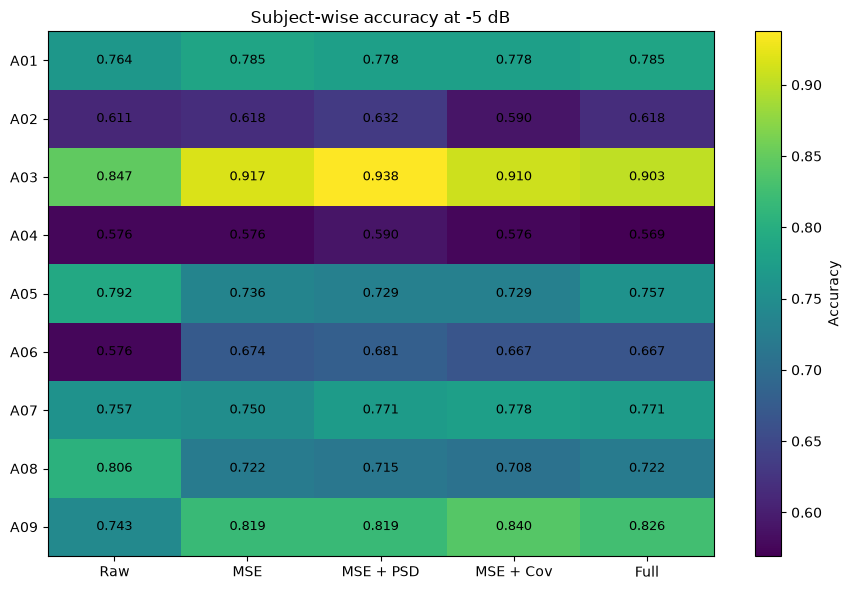

In [42]:
# ============================================================
# 34. SUBJECT-WISE ACCURACY HEATMAP
# ============================================================

pivot = (
    ablation_df
    .pivot(
        index="subject",
        columns="method",
        values="accuracy"
    )
    .reindex(
        columns=method_order
    )
)

arr = pivot.to_numpy(
    dtype=float
)

fig, ax = plt.subplots(
    figsize=(9, 6)
)

im = ax.imshow(
    arr,
    aspect="auto"
)

ax.set_xticks(
    np.arange(
        len(method_order)
    )
)

ax.set_xticklabels(
    [
        method_labels[m]
        for m in method_order
    ]
)

ax.set_yticks(
    np.arange(
        len(pivot.index)
    )
)

ax.set_yticklabels(
    pivot.index
)

for i in range(
    arr.shape[0]
):
    for j in range(
        arr.shape[1]
    ):

        ax.text(
            j,
            i,
            f"{arr[i, j]:.3f}",
            ha="center",
            va="center",
            fontsize=9
        )

ax.set_title(
    "Subject-wise accuracy at -5 dB"
)

fig.colorbar(
    im,
    ax=ax,
    label="Accuracy"
)

plt.tight_layout()
plt.show()

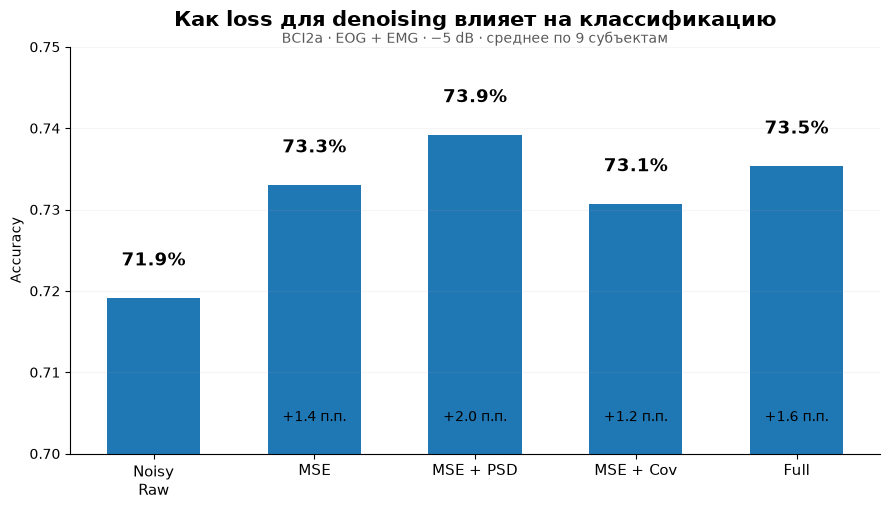

In [49]:
# ============================================================
# SIMPLE PRESENTATION PLOT
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

method_order = [
    "RAW",
    "MSE",
    "MSE_PSD",
    "MSE_COV",
    "FULL"
]

labels = [
    "Noisy\nRaw",
    "MSE",
    "MSE + PSD",
    "MSE + Cov",
    "Full"
]

means = (
    ablation_df
    .groupby("method")["accuracy"]
    .mean()
    .reindex(method_order)
    .values
)

raw = means[0]

gains = (
    means - raw
) * 100

x = np.arange(len(labels))

fig, ax = plt.subplots(figsize=(9, 5.2))

bars = ax.bar(
    x,
    means,
    width=0.58
)

# цифры accuracy
for i, value in enumerate(means):

    ax.text(
        i,
        value + 0.004,
        f"{value*100:.1f}%",
        ha="center",
        fontsize=13,
        fontweight="bold"
    )

# прирост относительно raw
for i in range(1, len(means)):

    ax.text(
        i,
        0.704,
        f"+{gains[i]:.1f} п.п.",
        ha="center",
        fontsize=10
    )

ax.set_ylim(
    0.70,
    0.75
)

ax.set_xticks(x)
ax.set_xticklabels(
    labels,
    fontsize=11
)

ax.set_ylabel(
    "Accuracy"
)

ax.set_title(
    "Как loss для denoising влияет на классификацию",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.text(
    0.5,
    1.01,
    "BCI2a · EOG + EMG · −5 dB · среднее по 9 субъектам",
    transform=ax.transAxes,
    ha="center",
    fontsize=10,
    alpha=0.65
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    axis="y",
    alpha=0.12
)

plt.tight_layout()
plt.show()

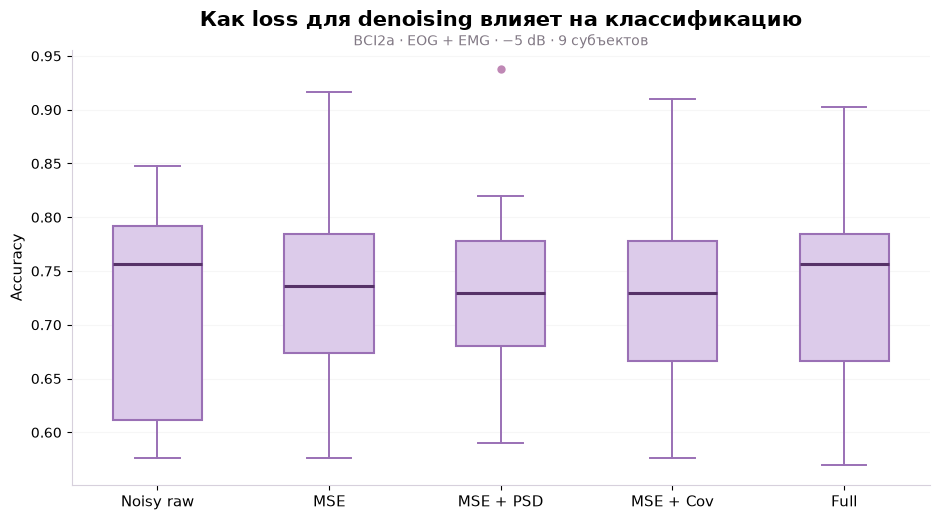

In [ ]:
# ============================================================
#  BOXPLOT 
# ============================================================

import matplotlib.pyplot as plt

method_order = [
    "RAW",
    "MSE",
    "MSE_PSD",
    "MSE_COV",
    "FULL"
]

labels = [
    "Noisy raw",
    "MSE",
    "MSE + PSD",
    "MSE + Cov",
    "Full"
]

data = [
    ablation_df.loc[
        ablation_df["method"] == method,
        "accuracy"
    ].values
    for method in method_order
]

fig, ax = plt.subplots(figsize=(9.5, 5.3))

bp = ax.boxplot(
    data,
    patch_artist=True,
    widths=0.52,
    showfliers=True,

    boxprops={
        "facecolor": "#DCCBEA",
        "edgecolor": "#9A70B5",
        "linewidth": 1.5
    },

    medianprops={
        "color": "#563268",
        "linewidth": 2.2
    },

    whiskerprops={
        "color": "#9A70B5",
        "linewidth": 1.4
    },

    capprops={
        "color": "#9A70B5",
        "linewidth": 1.4
    },

    flierprops={
        "marker": "o",
        "markerfacecolor": "#B06AA3",
        "markeredgecolor": "none",
        "markersize": 6,
        "alpha": 0.8
    }
)

ax.set_xticks(range(1, 6))
ax.set_xticklabels(
    labels,
    fontsize=11
)

ax.set_ylabel(
    "Accuracy",
    fontsize=11
)

ax.set_title(
    "Как loss для denoising влияет на классификацию",
    fontsize=15,
    fontweight="bold",
    pad=17
)

ax.text(
    0.5,
    1.01,
    "BCI2a · EOG + EMG · −5 dB · 9 субъектов",
    transform=ax.transAxes,
    ha="center",
    fontsize=10,
    color="#817884"
)

ax.grid(
    axis="y",
    alpha=0.10
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_color("#D7D0DC")
ax.spines["bottom"].set_color("#D7D0DC")

plt.tight_layout()
plt.show()

MSE — почему вообще использовать его в EEG denoising
1. EEGdenoiseNet: a benchmark dataset for deep learning solutions of EEG denoising — Zhang et al., Journal of Neural Engineering, 2021. Это как раз источник нашего набора EOG/EMG-артефактов. Авторы предлагают benchmark для обучения моделей noisy→clean EEG и оценивают качество восстановления по ошибкам реконструкции и другим denoising-метрикам. Это хороший базовый источник для идеи supervised reconstruction EEG. PubMed
   PubMed
2. EEG Signal Reconstruction Using a Generative Adversarial Network With Wasserstein Distance and Temporal-Spatial-Frequency Loss — 2020. Здесь прямо используется temporal MSE: point-wise ошибка между восстановленным и эталонным EEG. Авторы отдельно добавляют пространственные и частотные компоненты к MSE — по смыслу это очень близко к нашей логике «одного MSE недостаточно, надо сохранять ещё структуру сигнала». PubMed Central (PMC)
   Статья PMC
3. A novel EEG artifact removal algorithm based on an advanced attention mechanism — авторы прямо используют MSE как loss между исходным clean EEG и реконструированным EEG, объясняя это необходимостью минимизировать ошибку в каждой временной точке. PubMed Central (PMC)
   Статья PMC

Covariance — почему мы решили сохранять межканальную структуру
1. Multiclass Brain–Computer Interface Classification by Riemannian Geometry — Barachant et al., IEEE Transactions on Biomedical Engineering, 2012. Классическая работа: EEG trial представляется пространственной covariance matrix, которая содержит информацию о взаимосвязях между каналами; на BCI Competition IV 2a авторы показывают, что классификация непосредственно по covariance matrices конкурентоспособна и может превосходить CSP+LDA. IEEE Xplore
   IEEE Xplore
2. Robust Averaging of Covariances for EEG Recordings Classification in Motor Imagery Brain-Computer Interfaces — 2017. Авторы прямо пишут, что covariance matrices играют центральную роль в извлечении признаков MI-EEG, а качество их оценки существенно для классификации. PubMed
   PubMed
3. Classification of BCI-EEG Based on the Augmented Covariance Matrix — Carrara & Papadopoulo, IEEE Transactions on Biomedical Engineering, 2024. Работа специально развивает представление EEG через covariance matrix для улучшения motor-imagery classification. То есть это современное подтверждение, что пространственная covariance по-прежнему рассматривается как информативная характеристика MI-EEG. PubMed
   PubMed

PSD — да, для него тоже есть хорошее литературное обоснование, и как раз оно у нас самое прямое.
Три нормальных источника:
1. Most Popular Signal Processing Methods in Motor-Imagery BCI: A Review and Meta-Analysis. В обзоре прямо обсуждается, что motor imagery сопровождается изменением мощности сенсомоторных ритмов: μ примерно 8–12 Гц и β примерно 18–30 Гц. То есть анализ мощности по частотам — один из базовых способов описывать MI-EEG. Frontiers in Chemistry
2. A Comprehensive Review on Critical Issues and Possible Solutions of Motor Imagery Based EEG-BCI. Авторы отдельно пишут, что для MI часто используют полосовую фильтрацию 8–30 Гц, потому что этот диапазон содержит μ- и β-компоненты, связанные с моторными задачами. MDPI
3. Brain-Computer Interfaces Using Sensorimotor Rhythms: Current State and Future Perspectives. В обзоре описано, что motor imagery вызывает изменения мощности в μ- и β-диапазонах над сенсомоторной корой, и именно эти изменения лежат в основе SMR-BCI. PubMed Central (PMC)
То есть наше обоснование для PSD_loss можно сформулировать так:
В motor-imagery EEG информативны не только значения сигнала во времени, но и распределение мощности по частотам, особенно в μ/β-диапазоне около 8–30 Гц. Поэтому в loss была добавлена спектральная компонента, которая штрафует denoiser за искажение частотной структуры clean EEG.

## 6. Влияние типа артефакта на эффективность denoising

В предыдущем эксперименте denoiser обучался на полусинтетическом EEG,
загрязнённом смесью EOG- и EMG-артефактов.

Чтобы понять, на каком типе шума denoising работает лучше,
отдельно оцениваем три сценария:

- `EOG only` — глазные артефакты;
- `EMG only` — мышечные артефакты;
- `EOG + EMG` — смешанное загрязнение.

Для всех сценариев используется одинаковый уровень шума:

\[
SNR = -5 \text{ dB}
\]

Используется уже обученный denoiser с loss:

\[
MSE + PSD
\]

так как в предыдущем ablation study этот вариант показал
лучший средний downstream-результат.

Для каждого субъекта BCI Competition IV 2a сравниваются:

1. `RAW` — загрязнённый EEG без очистки;
2. `DENOISED` — тот же сигнал после обработки denoiser.

Оцениваются две группы метрик:

### Качество восстановления сигнала

- reconstruction SNR;
- RMSE.

### Сохранение информации для motor imagery

- accuracy;
- balanced accuracy;
- macro-F1;
- Cohen's kappa.

Для downstream-оценки используется ранее обученный
Cho2017-pretrained EEGNet classifier.

### Основной вопрос эксперимента

Одинаково ли denoiser справляется с EOG и EMG артефактами,
или его влияние на качество motor-imagery classification
зависит от типа загрязнения?

In [52]:
# ============================================================
# 35. FIXED NOISE BY ARTIFACT TYPE
# ============================================================

def make_artifact_by_type(
    artifact_type,
    target_length,
    rng
):
    if artifact_type == "EOG":

        return make_multichannel_eog(
            target_length,
            rng
        )

    elif artifact_type == "EMG":

        return make_multichannel_emg(
            target_length,
            rng
        )

    elif artifact_type == "EOG_EMG":

        return make_mixed_artifact(
            target_length,
            rng
        )

    else:

        raise ValueError(
            f"Unknown artifact type: {artifact_type}"
        )


def make_fixed_noisy_dataset_by_type(
    X_clean,
    artifact_type,
    snr_db=-5,
    seed=12345
):
    X_clean = np.asarray(
        X_clean,
        dtype=np.float32
    )

    X_noisy = []

    for idx, clean in enumerate(X_clean):

        rng = np.random.default_rng(
            seed + idx
        )

        artifact = make_artifact_by_type(
            artifact_type,
            clean.shape[-1],
            rng
        )

        noisy, _ = add_artifact_at_snr(
            clean,
            artifact,
            snr_db
        )

        X_noisy.append(
            noisy
        )

    return np.stack(
        X_noisy
    ).astype(np.float32)

In [53]:
for artifact_type in [
    "EOG",
    "EMG",
    "EOG_EMG"
]:

    X_tmp = (
        make_fixed_noisy_dataset_by_type(
            X_test_a01,
            artifact_type=artifact_type,
            snr_db=-5
        )
    )

    snr = dataset_snr_db(
        X_test_a01,
        X_tmp
    )

    print(
        artifact_type,
        round(snr.mean(), 4),
        "dB"
    )

EOG -5.0 dB
EMG -5.0 dB
EOG_EMG -5.0 dB


In [54]:
# ============================================================
# 36. ARTIFACT-TYPE EXPERIMENT — A01-A09
# ============================================================

import gc

ARTIFACT_TYPES = [
    "EOG",
    "EMG",
    "EOG_EMG"
]

artifact_results = []


for subject_num in range(1, 10):

    subject = f"A{subject_num:02d}"

    print(
        "\n" + "=" * 70
    )
    print(subject)
    print("=" * 70)


    # --------------------------------------------------------
    # LOAD SUBJECT
    # --------------------------------------------------------

    (
        X_train,
        X_val,
        X_test,
        y_train,
        y_val,
        y_test
    ) = prepare_subject_for_ablation(
        subject_num
    )


    # --------------------------------------------------------
    # BINARY MASKS
    # --------------------------------------------------------

    train_mask = (
        y_train < 2
    )

    test_mask = (
        y_test < 2
    )

    X_train_binary = (
        X_train[
            train_mask
        ]
    )

    y_test_binary = (
        y_test[
            test_mask
        ]
    )


    # --------------------------------------------------------
    # FIT FIXED CLASSIFIER PREPROCESSING ON CLEAN TRAIN
    # --------------------------------------------------------

    X_train_std = (
        trial_channel_standardize(
            X_train_binary
        )
    )

    EA_W = compute_ea_whitener(
        X_train_std
    )

    X_train_ea = apply_ea(
        X_train_std,
        EA_W
    )

    GLOBAL_MEAN = (
        X_train_ea.mean()
    )

    GLOBAL_STD = (
        X_train_ea.std()
        + 1e-8
    )


    # --------------------------------------------------------
    # LOAD PRETRAINED CLASSIFIER
    # --------------------------------------------------------

    classifier_path = os.path.join(
        CLASSIFIER_DIR,
        f"{subject}_pretrained_classifier.pt"
    )

    classifier = UnifiedEEGNet(
        n_channels=22,
        n_classes=2
    ).to(
        classifier_device
    )

    classifier.load_state_dict(
        torch.load(
            classifier_path,
            map_location=classifier_device
        )
    )

    classifier.eval()


    # --------------------------------------------------------
    # LOAD BEST ABLATION DENOISER: MSE + PSD
    # --------------------------------------------------------

    denoiser_path = os.path.join(
        ABLATION_MODEL_DIR,
        f"{subject}_MSE_PSD.pt"
    )

    denoiser = (
        MultichannelResidualDenoiser(
            n_channels=22,
            hidden=64
        )
        .to(
            denoiser_device
        )
    )

    denoiser.load_state_dict(
        torch.load(
            denoiser_path,
            map_location=denoiser_device
        )
    )

    denoiser.eval()


    # --------------------------------------------------------
    # TEST 3 ARTIFACT TYPES
    # --------------------------------------------------------

    for artifact_type in ARTIFACT_TYPES:

        X_noisy = (
            make_fixed_noisy_dataset_by_type(
                X_test,
                artifact_type=artifact_type,
                snr_db=-5,
                seed=12345
            )
        )

        X_denoised = (
            apply_denoiser_to_dataset(
                denoiser,
                X_noisy
            )
        )


        for processing, X_signal in [
            ("RAW", X_noisy),
            ("DENOISED", X_denoised)
        ]:

            X_binary = (
                X_signal[
                    test_mask
                ]
            )

            X_clean_binary = (
                X_test[
                    test_mask
                ]
            )


            # reconstruction
            recon = (
                reconstruction_metrics(
                    X_clean_binary,
                    X_binary
                )
            )


            # classifier preprocessing
            X_proc = (
                preprocess_for_classifier(
                    X_binary,
                    EA_W,
                    GLOBAL_MEAN,
                    GLOBAL_STD
                )
            )


            cls = evaluate_classifier(
                classifier,
                X_proc,
                y_test_binary
            )


            artifact_results.append({

                "subject":
                    subject,

                "artifact":
                    artifact_type,

                "processing":
                    processing,

                "accuracy":
                    cls["accuracy"],

                "balanced_accuracy":
                    cls[
                        "balanced_accuracy"
                    ],

                "macro_f1":
                    cls["macro_f1"],

                "kappa":
                    cls["kappa"],

                "reconstruction_snr_db":
                    recon["SNR_dB"],

                "rmse_uV":
                    recon["RMSE"] * 1e6
            })


        print(
            subject,
            artifact_type,
            "done"
        )


    del classifier
    del denoiser

    gc.collect()

    if torch.backends.mps.is_available():
        torch.mps.empty_cache()


artifact_df = pd.DataFrame(
    artifact_results
)


ARTIFACT_RESULTS_PATH = os.path.join(
    ABLATION_DIR,
    "artifact_type_results.csv"
)

artifact_df.to_csv(
    ARTIFACT_RESULTS_PATH,
    index=False
)


print(
    "\nSaved:",
    ARTIFACT_RESULTS_PATH
)

print(
    "Rows:",
    len(artifact_df)
)


A01
A01 EOG done
A01 EMG done
A01 EOG_EMG done

A02
A02 EOG done
A02 EMG done
A02 EOG_EMG done

A03
A03 EOG done
A03 EMG done
A03 EOG_EMG done

A04
A04 EOG done
A04 EMG done
A04 EOG_EMG done

A05
A05 EOG done
A05 EMG done
A05 EOG_EMG done

A06
A06 EOG done
A06 EMG done
A06 EOG_EMG done

A07
A07 EOG done
A07 EMG done
A07 EOG_EMG done

A08
A08 EOG done
A08 EMG done
A08 EOG_EMG done

A09
A09 EOG done
A09 EMG done
A09 EOG_EMG done

Saved: /Users/irina/Desktop/master project/results_v2/ablation_task_informed/artifact_type_results.csv
Rows: 54


In [55]:
# ============================================================
# 37. ARTIFACT TYPE SUMMARY
# ============================================================

artifact_summary = (
    artifact_df
    .groupby(
        [
            "artifact",
            "processing"
        ]
    )
    [
        [
            "accuracy",
            "balanced_accuracy",
            "macro_f1",
            "reconstruction_snr_db"
        ]
    ]
    .mean()
    .round(4)
)

artifact_summary

accuracy  balanced_accuracy  macro_f1  \
artifact processing                                          
EMG      DENOISED      0.6991             0.6991    0.6860   
         RAW           0.6944             0.6944    0.6817   
EOG      DENOISED      0.8441             0.8441    0.8431   
         RAW           0.6582             0.6582    0.6073   
EOG_EMG  DENOISED      0.7392             0.7392    0.7317   
         RAW           0.7191             0.7191    0.7085   

                     reconstruction_snr_db  
artifact processing                         
EMG      DENOISED                   2.7050  
         RAW                       -5.0000  
EOG      DENOISED                   9.0754  
         RAW                       -5.0000  
EOG_EMG  DENOISED                   4.0046  
         RAW                       -5.0000

### Сравнение RAW и DENOISED

Для каждого типа артефакта рассчитываем средние метрики по 9 субъектам
и отдельно оцениваем изменение accuracy после denoising.

Положительный `accuracy gain` означает, что очистка улучшила
downstream-классификацию относительно исходного noisy EEG.

In [56]:
accuracy_artifact_pivot = (
    artifact_df
    .pivot(
        index=[
            "subject",
            "artifact"
        ],
        columns="processing",
        values="accuracy"
    )
    .reset_index()
)

accuracy_artifact_pivot[
    "gain_pp"
] = (
    accuracy_artifact_pivot[
        "DENOISED"
    ]
    -
    accuracy_artifact_pivot[
        "RAW"
    ]
) * 100


gain_summary = (
    accuracy_artifact_pivot
    .groupby(
        "artifact"
    )["gain_pp"]
    .agg(
        [
            "mean",
            "median"
        ]
    )
    .round(2)
)

gain_summary

,mean,median
artifact,,
EMG,0.46,-0.69
EOG,18.60,15.28
EOG_EMG,2.01,1.39


In [57]:
# ============================================================
# 38. ABSOLUTE ACCURACY + SNR BY ARTIFACT TYPE
# ============================================================

artifact_check = (
    artifact_df
    .groupby(
        ["artifact", "processing"]
    )
    .agg(
        accuracy_mean=("accuracy", "mean"),
        accuracy_median=("accuracy", "median"),
        balanced_accuracy_mean=("balanced_accuracy", "mean"),
        macro_f1_mean=("macro_f1", "mean"),
        snr_mean=("reconstruction_snr_db", "mean"),
        rmse_uV_mean=("rmse_uV", "mean")
    )
    .reset_index()
)

artifact_check.round(4)

,artifact,processing,accuracy_mean,accuracy_median,balanced_accuracy_mean,macro_f1_mean,snr_mean,rmse_uV_mean
0,EMG,DENOISED,0.6991,0.6944,0.6991,0.6860,2.7050,8.363300
1,EMG,RAW,0.6944,0.7361,0.6944,0.6817,-5.0000,19.822201
2,EOG,DENOISED,0.8441,0.8611,0.8441,0.8431,9.0754,4.028700
3,EOG,RAW,0.6582,0.6389,0.6582,0.6073,-5.0000,19.822201
4,EOG_EMG,DENOISED,0.7392,0.7292,0.7392,0.7317,4.0046,7.196300
5,EOG_EMG,RAW,0.7191,0.7569,0.7191,0.7085,-5.0000,19.822201


In [58]:
# Accuracy RAW vs DENOISED

accuracy_table = (
    artifact_df
    .pivot_table(
        index="artifact",
        columns="processing",
        values="accuracy",
        aggfunc="mean"
    )
)

accuracy_table["gain_pp"] = (
    accuracy_table["DENOISED"]
    - accuracy_table["RAW"]
) * 100

accuracy_table.round(4)

processing,DENOISED,RAW,gain_pp
artifact,,,
EMG,0.6991,0.6944,0.4630
EOG,0.8441,0.6582,18.5957
EOG_EMG,0.7392,0.7191,2.0062


In [59]:
# Reconstruction SNR RAW vs DENOISED

snr_table = (
    artifact_df
    .pivot_table(
        index="artifact",
        columns="processing",
        values="reconstruction_snr_db",
        aggfunc="mean"
    )
)

snr_table["gain_dB"] = (
    snr_table["DENOISED"]
    - snr_table["RAW"]
)

snr_table.round(3)

processing,DENOISED,RAW,gain_dB
artifact,,,
EMG,2.705,-5.0,7.705
EOG,9.075,-5.0,14.075
EOG_EMG,4.005,-5.0,9.005


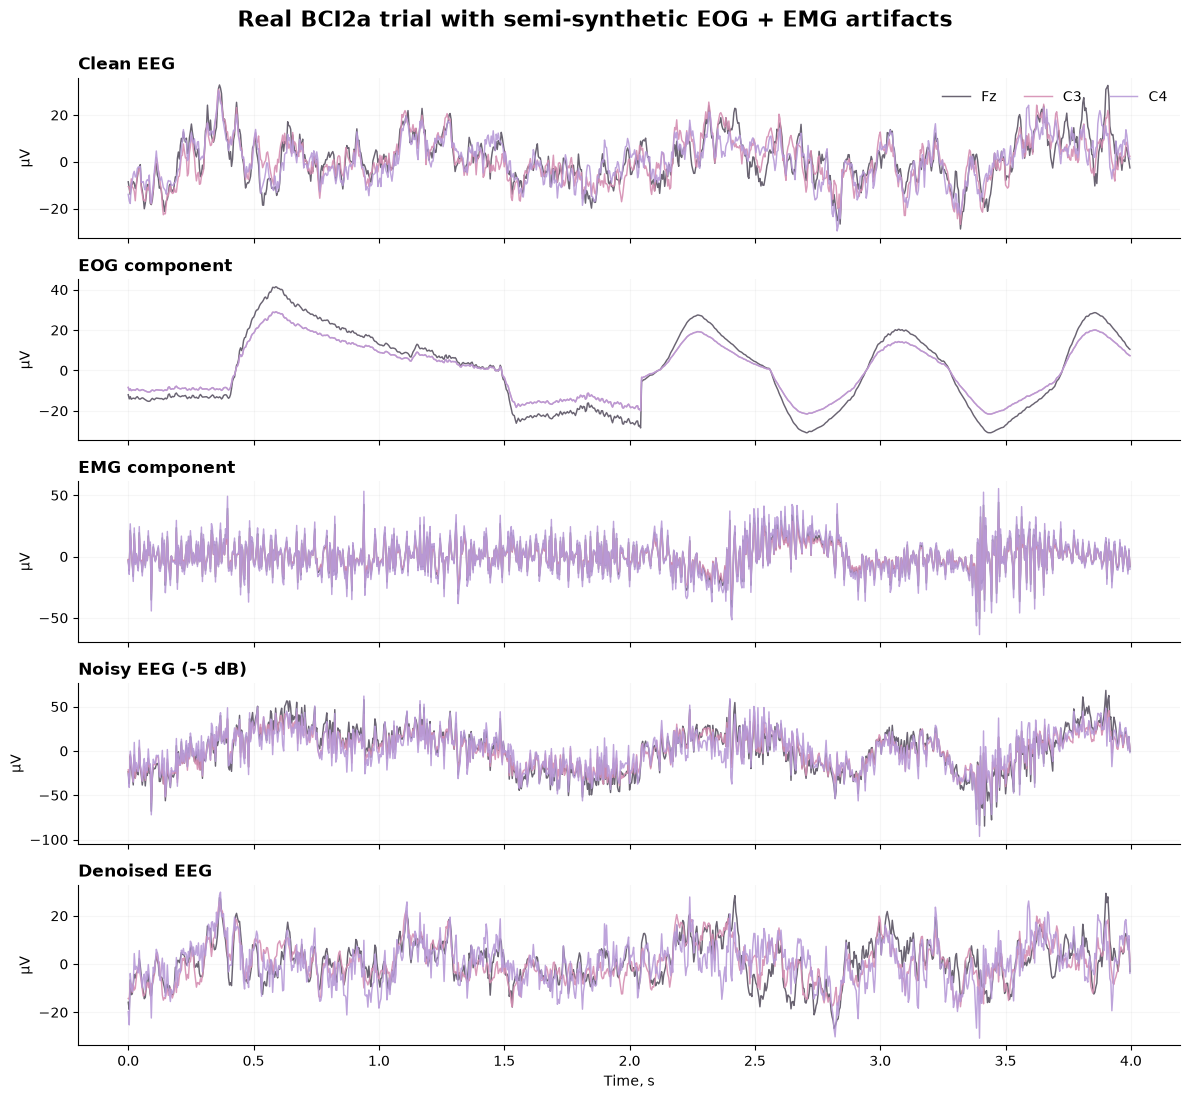

Input SNR: -5.0 dB
Denoised SNR: 4.76 dB


In [60]:
# ============================================================
# 39. REAL EEG EXAMPLE:
# CLEAN / EOG / EMG / NOISY / DENOISED
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt
import torch


CHANNEL_NAMES = [
    "Fz",
    "FC3", "FC1", "FCz", "FC2", "FC4",
    "C5", "C3", "C1", "Cz", "C2", "C4", "C6",
    "CP3", "CP1", "CPz", "CP2", "CP4",
    "P1", "Pz", "P2", "POz"
]


# ------------------------------------------------------------
# Берём один настоящий BCI2a trial
# ------------------------------------------------------------

TRIAL_IDX = 0
TARGET_SNR = -5
VIS_SEED = 2026

clean = X_test_a01[
    TRIAL_IDX
].copy()


# ------------------------------------------------------------
# Создаём EOG и EMG отдельно
# ------------------------------------------------------------

rng = np.random.default_rng(
    VIS_SEED
)

eog_raw = make_multichannel_eog(
    clean.shape[-1],
    rng
)

emg_raw = make_multichannel_emg(
    clean.shape[-1],
    rng
)


# именно та смесь, которую подаём в noisy EEG
mixed_raw = (
    0.5 * eog_raw
    +
    0.5 * emg_raw
)


# ------------------------------------------------------------
# Масштабируем всю смесь до -5 dB
# ------------------------------------------------------------

signal_power = np.mean(
    clean ** 2
)

artifact_power = (
    np.mean(
        mixed_raw ** 2
    )
    + 1e-20
)

target_noise_power = (
    signal_power
    /
    (10 ** (TARGET_SNR / 10))
)

scale = np.sqrt(
    target_noise_power
    / artifact_power
)


eog_component = (
    0.5 * eog_raw * scale
)

emg_component = (
    0.5 * emg_raw * scale
)

mixed_artifact = (
    eog_component
    +
    emg_component
)

noisy = (
    clean
    +
    mixed_artifact
).astype(np.float32)


# ------------------------------------------------------------
# Загружаем A01 MSE+PSD denoiser
# ------------------------------------------------------------

model_path = os.path.join(
    ABLATION_MODEL_DIR,
    "A01_MSE_PSD.pt"
)

vis_denoiser = (
    MultichannelResidualDenoiser(
        n_channels=22,
        hidden=64
    )
    .to(denoiser_device)
)

vis_denoiser.load_state_dict(
    torch.load(
        model_path,
        map_location=denoiser_device
    )
)

vis_denoiser.eval()


# ------------------------------------------------------------
# Denoising
# ------------------------------------------------------------

scale_input = (
    noisy.std()
    + 1e-8
)

noisy_norm = (
    noisy / scale_input
)

x = torch.tensor(
    noisy_norm[None],
    dtype=torch.float32,
    device=denoiser_device
)

with torch.no_grad():

    denoised_norm = vis_denoiser(
        x
    )

denoised = (
    denoised_norm[0]
    .cpu()
    .numpy()
    * scale_input
)


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

time = (
    np.arange(
        clean.shape[-1]
    )
    / SFREQ
)

# три понятных канала:
# Fz — хорошо видно EOG
# C3/C4 — сенсомоторная зона
channels_to_plot = [
    0,   # Fz
    7,   # C3
    11   # C4
]

signals = [
    ("Clean EEG", clean),
    ("EOG component", eog_component),
    ("EMG component", emg_component),
    ("Noisy EEG (-5 dB)", noisy),
    ("Denoised EEG", denoised)
]

fig, axes = plt.subplots(
    5,
    1,
    figsize=(12, 11),
    sharex=True
)

plot_colors = [
    "#5A5363",
    "#D58EB2",
    "#B79AD8"
]

for ax, (title, signal) in zip(
    axes,
    signals
):

    for channel_idx, color in zip(
        channels_to_plot,
        plot_colors
    ):

        ax.plot(
            time,
            signal[channel_idx] * 1e6,
            linewidth=1.05,
            alpha=0.90,
            color=color,
            label=CHANNEL_NAMES[channel_idx]
        )

    ax.set_title(
        title,
        loc="left",
        fontsize=12,
        fontweight="bold"
    )

    ax.set_ylabel(
        "µV"
    )

    ax.grid(
        alpha=0.10
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


axes[0].legend(
    frameon=False,
    ncol=3,
    loc="upper right"
)

axes[-1].set_xlabel(
    "Time, s"
)

fig.suptitle(
    "Real BCI2a trial with semi-synthetic EOG + EMG artifacts",
    fontsize=16,
    fontweight="bold",
    y=0.995
)

plt.tight_layout()
plt.show()


print(
    "Input SNR:",
    round(
        dataset_snr_db(
            clean[None],
            noisy[None]
        )[0],
        3
    ),
    "dB"
)

print(
    "Denoised SNR:",
    round(
        reconstruction_metrics(
            clean[None],
            denoised[None]
        )["SNR_dB"],
        3
    ),
    "dB"
)

## 7. Artifact-specific denoising

Предыдущий эксперимент показал сильную зависимость эффективности denoising
от типа артефакта.

При одинаковом входном SNR = −5 dB:

| Artifact | Raw accuracy | Denoised accuracy | Gain |
|---|---:|---:|---:|
| EOG | 65.8% | 84.4% | +18.6 pp |
| EMG | 69.4% | 69.9% | +0.5 pp |
| EOG + EMG | 71.9% | 73.9% | +2.0 pp |

При этом текущий denoiser обучался на смеси EOG + EMG.

### Research question

Связано ли слабое улучшение на EMG с тем,
что универсальный mixed-denoiser недостаточно хорошо изучает EMG-компоненту,
или EMG является более сложным типом артефакта для отделения от MI-EEG?

Для проверки обучаются два дополнительных типа моделей:

1. EOG-specific denoiser:
   noisy EEG = clean EEG + EOG → target = clean EEG

2. EMG-specific denoiser:
   noisy EEG = clean EEG + EMG → target = clean EEG

Существующая mixed-модель используется как третий вариант:

3. Mixed denoiser:
   noisy EEG = clean EEG + EOG + EMG → target = clean EEG

Во всех случаях используется одинаковая архитектура и loss:

\[
L = MSE + 0.1 \cdot PSD_{8-30Hz}
\]

После обучения модели будут cross-tested на EOG, EMG и EOG+EMG.

In [61]:
# ============================================================
# 40. ARTIFACT-SPECIFIC TRAINING DATASET
# ============================================================

class ArtifactSpecificDenoisingDataset(Dataset):

    def __init__(
        self,
        X_clean,
        artifact_type,
        snr_min=-5,
        snr_max=5,
        deterministic=False,
        seed=42
    ):

        self.X_clean = np.asarray(
            X_clean,
            dtype=np.float32
        )

        self.artifact_type = artifact_type

        self.snr_min = snr_min
        self.snr_max = snr_max

        self.deterministic = deterministic
        self.seed = seed


    def __len__(self):
        return len(self.X_clean)


    def __getitem__(self, idx):

        clean = self.X_clean[
            idx
        ].copy()


        if self.deterministic:

            rng = np.random.default_rng(
                self.seed + idx
            )

        else:

            rng = np.random.default_rng()


        snr_db = rng.uniform(
            self.snr_min,
            self.snr_max
        )


        artifact = make_artifact_by_type(
            self.artifact_type,
            clean.shape[-1],
            rng
        )


        noisy, _ = add_artifact_at_snr(
            clean,
            artifact,
            snr_db
        )


        scale = (
            noisy.std()
            + 1e-8
        )

        noisy_norm = (
            noisy / scale
        ).astype(np.float32)

        clean_norm = (
            clean / scale
        ).astype(np.float32)


        return (
            torch.tensor(
                noisy_norm,
                dtype=torch.float32
            ),
            torch.tensor(
                clean_norm,
                dtype=torch.float32
            )
        )

In [62]:
# ============================================================
# 41. TRAIN ARTIFACT-SPECIFIC DENOISER
# ============================================================

def train_artifact_specific_denoiser(
    X_train,
    X_val,
    artifact_type,
    subject,
    epochs=150,
    batch_size=16,
    lr=1e-3,
    patience=20,
    seed=42
):

    set_seed(seed)


    train_ds = ArtifactSpecificDenoisingDataset(
        X_train,
        artifact_type=artifact_type,
        snr_min=-5,
        snr_max=5,
        deterministic=False,
        seed=seed
    )


    val_ds = ArtifactSpecificDenoisingDataset(
        X_val,
        artifact_type=artifact_type,
        snr_min=-5,
        snr_max=5,
        deterministic=True,
        seed=seed + 10000
    )


    train_loader = DataLoader(
        train_ds,
        batch_size=batch_size,
        shuffle=True,
        num_workers=0
    )


    val_loader = DataLoader(
        val_ds,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0
    )


    model = MultichannelResidualDenoiser(
        n_channels=22,
        hidden=64
    ).to(
        denoiser_device
    )


    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=lr
    )


    best_val = np.inf
    best_state = None

    bad_epochs = 0

    history = []


    for epoch in range(
        1,
        epochs + 1
    ):

        # ========================
        # TRAIN
        # ========================

        model.train()

        train_loss = 0.0
        n_train = 0


        for noisy, clean in train_loader:

            noisy = noisy.to(
                denoiser_device
            )

            clean = clean.to(
                denoiser_device
            )


            optimizer.zero_grad()


            pred = model(
                noisy
            )


            loss = (
                mse_loss(
                    pred,
                    clean
                )
                +
                0.1
                * spectral_loss(
                    pred,
                    clean,
                    sfreq=SFREQ,
                    fmin=8,
                    fmax=30
                )
            )


            loss.backward()

            optimizer.step()


            bs = noisy.shape[0]

            train_loss += (
                loss.item()
                * bs
            )

            n_train += bs


        train_loss /= n_train


        # ========================
        # VALIDATION
        # ========================

        model.eval()

        val_loss = 0.0
        n_val = 0


        with torch.no_grad():

            for noisy, clean in val_loader:

                noisy = noisy.to(
                    denoiser_device
                )

                clean = clean.to(
                    denoiser_device
                )


                pred = model(
                    noisy
                )


                loss = (
                    mse_loss(
                        pred,
                        clean
                    )
                    +
                    0.1
                    * spectral_loss(
                        pred,
                        clean,
                        sfreq=SFREQ,
                        fmin=8,
                        fmax=30
                    )
                )


                bs = noisy.shape[0]

                val_loss += (
                    loss.item()
                    * bs
                )

                n_val += bs


        val_loss /= n_val


        history.append({
            "epoch":
                epoch,

            "train_loss":
                train_loss,

            "val_loss":
                val_loss
        })


        # ========================
        # EARLY STOPPING
        # ========================

        if val_loss < best_val:

            best_val = val_loss

            best_state = copy.deepcopy(
                model.state_dict()
            )

            bad_epochs = 0

        else:

            bad_epochs += 1


        if (
            epoch == 1
            or epoch % 10 == 0
        ):

            print(
                f"{subject} | "
                f"{artifact_type:3s} | "
                f"epoch {epoch:3d} | "
                f"train={train_loss:.4f} | "
                f"val={val_loss:.4f}"
            )


        if bad_epochs >= patience:

            print(
                f"{subject} | "
                f"{artifact_type} | "
                f"early stop {epoch}"
            )

            break


    model.load_state_dict(
        best_state
    )


    return (
        model,
        pd.DataFrame(history),
        best_val
    )

In [63]:
# ============================================================
# 42. OVERNIGHT TRAINING
# EOG-SPECIFIC + EMG-SPECIFIC
# A01-A09
# ============================================================

import gc


SPECIFIC_MODEL_DIR = os.path.join(
    MODEL_DIR,
    "artifact_specific_denoising"
)

SPECIFIC_RESULTS_DIR = os.path.join(
    RESULTS_DIR,
    "artifact_specific_denoising"
)

os.makedirs(
    SPECIFIC_MODEL_DIR,
    exist_ok=True
)

os.makedirs(
    SPECIFIC_RESULTS_DIR,
    exist_ok=True
)


TRAIN_ARTIFACT_TYPES = [
    "EOG",
    "EMG"
]


training_summary = []


for subject_num in range(
    1,
    10
):

    subject = f"A{subject_num:02d}"


    print(
        "\n"
        + "=" * 80
    )

    print(
        "SUBJECT:",
        subject
    )

    print(
        "=" * 80
    )


    (
        X_train,
        X_val,
        X_test,
        y_train,
        y_val,
        y_test
    ) = prepare_subject_for_ablation(
        subject_num
    )


    for artifact_type in TRAIN_ARTIFACT_TYPES:

        model_path = os.path.join(
            SPECIFIC_MODEL_DIR,
            f"{subject}_{artifact_type}_MSE_PSD.pt"
        )

        history_path = os.path.join(
            SPECIFIC_RESULTS_DIR,
            f"{subject}_{artifact_type}_history.csv"
        )


        # ----------------------------------------
        # resume-safe
        # ----------------------------------------

        if os.path.exists(
            model_path
        ):

            print(
                subject,
                artifact_type,
                "already exists -> skip"
            )

            continue


        print(
            "\nTraining",
            subject,
            artifact_type
        )


        model, history_df, best_val = (
            train_artifact_specific_denoiser(
                X_train=X_train,
                X_val=X_val,
                artifact_type=artifact_type,
                subject=subject,
                epochs=150,
                batch_size=16,
                lr=1e-3,
                patience=20,
                seed=42
            )
        )


        torch.save(
            model.state_dict(),
            model_path
        )


        history_df.to_csv(
            history_path,
            index=False
        )


        training_summary.append({
            "subject":
                subject,

            "artifact_type":
                artifact_type,

            "best_val_loss":
                best_val,

            "epochs":
                len(history_df)
        })


        pd.DataFrame(
            training_summary
        ).to_csv(
            os.path.join(
                SPECIFIC_RESULTS_DIR,
                "training_summary.csv"
            ),
            index=False
        )


        print(
            "SAVED:",
            model_path
        )


        del model

        gc.collect()


        if torch.backends.mps.is_available():

            torch.mps.empty_cache()


print(
    "\n"
    + "=" * 80
)

print(
    "OVERNIGHT TRAINING FINISHED"
)

print(
    "=" * 80
)


SUBJECT: A01

Training A01 EOG
A01 | EOG | epoch   1 | train=0.3105 | val=0.1702
A01 | EOG | epoch  10 | train=0.0659 | val=0.0702
A01 | EOG | epoch  20 | train=0.0591 | val=0.0741
A01 | EOG | epoch  30 | train=0.0551 | val=0.0616
A01 | EOG | epoch  40 | train=0.0539 | val=0.0580
A01 | EOG | epoch  50 | train=0.0535 | val=0.0808
A01 | EOG | epoch  60 | train=0.0513 | val=0.0601
A01 | EOG | epoch  70 | train=0.0499 | val=0.0543
A01 | EOG | epoch  80 | train=0.0512 | val=0.0916
A01 | EOG | epoch  90 | train=0.0486 | val=0.0497
A01 | EOG | epoch 100 | train=0.0498 | val=0.0671
A01 | EOG | early stop 106
SAVED: /Users/irina/Desktop/master project/models_v2/artifact_specific_denoising/A01_EOG_MSE_PSD.pt

Training A01 EMG
A01 | EMG | epoch   1 | train=0.5216 | val=0.4428
A01 | EMG | epoch  10 | train=0.2667 | val=0.2626
A01 | EMG | epoch  20 | train=0.2488 | val=0.2560
A01 | EMG | epoch  30 | train=0.2465 | val=0.2531
A01 | EMG | epoch  40 | train=0.2483 | val=0.2623
A01 | EMG | epoch  50 |

## 8. Итоговые таблицы artifact-specific experiment

После обучения сравниваются три типа denoiser:

- `EOG-trained`
- `EMG-trained`
- `Mixed-trained`

Каждый вариант тестируется на трёх типах артефактов:

- EOG
- EMG
- EOG + EMG

Для каждого сочетания считаются:

- accuracy;
- balanced accuracy;
- macro-F1;
- Cohen's kappa;
- reconstruction SNR;
- RMSE.

Итоговая цель — получить матрицу:

| Train \ Test | EOG | EMG | EOG + EMG |
|---|---:|---:|---:|
| EOG-trained |  |  |  |
| EMG-trained |  |  |  |
| Mixed-trained |  |  |  |

и отдельно сравнить качество реконструкции сигнала.

In [64]:
# ============================================================
# 43. PREPARE SUMMARY TABLES
# ============================================================

TRAIN_TYPES = [
    "EOG",
    "EMG",
    "MIXED"
]

TEST_TYPES = [
    "EOG",
    "EMG",
    "EOG_EMG"
]


accuracy_matrix = pd.DataFrame(
    index=TRAIN_TYPES,
    columns=TEST_TYPES,
    dtype=float
)

snr_matrix = pd.DataFrame(
    index=TRAIN_TYPES,
    columns=TEST_TYPES,
    dtype=float
)

f1_matrix = pd.DataFrame(
    index=TRAIN_TYPES,
    columns=TEST_TYPES,
    dtype=float
)

kappa_matrix = pd.DataFrame(
    index=TRAIN_TYPES,
    columns=TEST_TYPES,
    dtype=float
)


print("Accuracy matrix")
display(accuracy_matrix)

print("\nSNR matrix")
display(snr_matrix)

Accuracy matrix


,EOG,EMG,EOG_EMG
EOG,NaN,NaN,NaN
EMG,NaN,NaN,NaN
MIXED,NaN,NaN,NaN



SNR matrix


,EOG,EMG,EOG_EMG
EOG,NaN,NaN,NaN
EMG,NaN,NaN,NaN
MIXED,NaN,NaN,NaN


In [65]:
# ============================================================
# 44. FINAL CROSS-TEST PATH
# ============================================================

CROSS_TEST_RESULTS_PATH = os.path.join(
    SPECIFIC_RESULTS_DIR,
    "artifact_cross_test_results.csv"
)

print(
    "Cross-test results will be saved to:",
    CROSS_TEST_RESULTS_PATH
)

Cross-test results will be saved to: /Users/irina/Desktop/master project/results_v2/artifact_specific_denoising/artifact_cross_test_results.csv


In [66]:
# ============================================================
# 45. BUILD SUMMARY TABLES FROM CROSS-TEST RESULTS
# ============================================================

def build_cross_test_tables(
    cross_df
):

    accuracy_matrix = (
        cross_df
        .groupby(
            [
                "train_artifact",
                "test_artifact"
            ]
        )["accuracy"]
        .mean()
        .unstack()
        .reindex(
            index=[
                "EOG",
                "EMG",
                "MIXED"
            ],
            columns=[
                "EOG",
                "EMG",
                "EOG_EMG"
            ]
        )
    )


    snr_matrix = (
        cross_df
        .groupby(
            [
                "train_artifact",
                "test_artifact"
            ]
        )["reconstruction_snr_db"]
        .mean()
        .unstack()
        .reindex(
            index=[
                "EOG",
                "EMG",
                "MIXED"
            ],
            columns=[
                "EOG",
                "EMG",
                "EOG_EMG"
            ]
        )
    )


    f1_matrix = (
        cross_df
        .groupby(
            [
                "train_artifact",
                "test_artifact"
            ]
        )["macro_f1"]
        .mean()
        .unstack()
        .reindex(
            index=[
                "EOG",
                "EMG",
                "MIXED"
            ],
            columns=[
                "EOG",
                "EMG",
                "EOG_EMG"
            ]
        )
    )


    kappa_matrix = (
        cross_df
        .groupby(
            [
                "train_artifact",
                "test_artifact"
            ]
        )["kappa"]
        .mean()
        .unstack()
        .reindex(
            index=[
                "EOG",
                "EMG",
                "MIXED"
            ],
            columns=[
                "EOG",
                "EMG",
                "EOG_EMG"
            ]
        )
    )


    return (
        accuracy_matrix,
        snr_matrix,
        f1_matrix,
        kappa_matrix
    )

In [67]:
# ============================================================
# 46. DISPLAY FINAL MATRICES
# ============================================================

if os.path.exists(
    CROSS_TEST_RESULTS_PATH
):

    cross_df = pd.read_csv(
        CROSS_TEST_RESULTS_PATH
    )

    (
        accuracy_matrix,
        snr_matrix,
        f1_matrix,
        kappa_matrix
    ) = build_cross_test_tables(
        cross_df
    )


    print("\nMEAN ACCURACY")
    display(
        accuracy_matrix.round(4)
    )


    print("\nMEAN RECONSTRUCTION SNR")
    display(
        snr_matrix.round(3)
    )


    print("\nMEAN MACRO-F1")
    display(
        f1_matrix.round(4)
    )


    print("\nMEAN KAPPA")
    display(
        kappa_matrix.round(4)
    )

else:

    print(
        "Cross-test results not generated yet."
    )

Cross-test results not generated yet.


In [68]:
# ============================================================
# 47. ACCURACY GAIN VS RAW
# ============================================================

def build_gain_table(
    cross_df,
    raw_df
):

    model_acc = (
        cross_df
        .groupby(
            [
                "train_artifact",
                "test_artifact"
            ]
        )["accuracy"]
        .mean()
        .unstack()
    )

    raw_acc = (
        raw_df
        .groupby(
            "artifact"
        )["accuracy"]
        .mean()
    )

    gain = model_acc.copy()

    for test_artifact in gain.columns:

        gain[
            test_artifact
        ] = (
            gain[
                test_artifact
            ]
            -
            raw_acc[
                test_artifact
            ]
        ) * 100

    return gain


# raw_df можно будет получить из сегодняшнего artifact_df:
raw_only_df = (
    artifact_df[
        artifact_df[
            "processing"
        ] == "RAW"
    ]
    .rename(
        columns={
            "artifact":
                "test_artifact"
        }
    )
)

In [69]:
# ============================================================
# 48. CROSS-TEST ALL TRAINED DENOISERS
#
# train:
#   EOG-specific
#   EMG-specific
#   MIXED (existing MSE+PSD)
#
# test:
#   EOG
#   EMG
#   EOG+EMG
# ============================================================

import os
import gc
import numpy as np
import pandas as pd
import torch


TRAIN_TYPES = [
    "EOG",
    "EMG",
    "MIXED"
]

TEST_TYPES = [
    "EOG",
    "EMG",
    "EOG_EMG"
]


cross_results = []


for subject_num in range(1, 10):

    subject = f"A{subject_num:02d}"

    print("\n" + "=" * 80)
    print("SUBJECT:", subject)
    print("=" * 80)


    # --------------------------------------------------------
    # LOAD BCI2a SUBJECT
    # --------------------------------------------------------

    (
        X_train,
        X_val,
        X_test,
        y_train,
        y_val,
        y_test
    ) = prepare_subject_for_ablation(
        subject_num
    )


    # --------------------------------------------------------
    # BINARY LEFT / RIGHT ONLY
    # --------------------------------------------------------

    train_mask = (
        y_train < 2
    )

    test_mask = (
        y_test < 2
    )

    X_train_binary = (
        X_train[
            train_mask
        ]
    )

    X_test_clean_binary = (
        X_test[
            test_mask
        ]
    )

    y_test_binary = (
        y_test[
            test_mask
        ]
    )


    # --------------------------------------------------------
    # CLASSIFIER PREPROCESSING
    # FIT ONLY ON CLEAN TRAIN
    # --------------------------------------------------------

    X_train_std = (
        trial_channel_standardize(
            X_train_binary
        )
    )

    EA_W = compute_ea_whitener(
        X_train_std
    )

    X_train_ea = apply_ea(
        X_train_std,
        EA_W
    )

    GLOBAL_MEAN = (
        X_train_ea.mean()
    )

    GLOBAL_STD = (
        X_train_ea.std()
        + 1e-8
    )


    # --------------------------------------------------------
    # LOAD SUBJECT-SPECIFIC PRETRAINED CLASSIFIER
    # --------------------------------------------------------

    classifier_path = os.path.join(
        CLASSIFIER_DIR,
        f"{subject}_pretrained_classifier.pt"
    )

    classifier = UnifiedEEGNet(
        n_channels=22,
        n_classes=2
    ).to(
        classifier_device
    )

    classifier.load_state_dict(
        torch.load(
            classifier_path,
            map_location=classifier_device
        )
    )

    classifier.eval()


    # --------------------------------------------------------
    # MAKE THREE FIXED TEST SETS
    # identical for all denoisers
    # --------------------------------------------------------

    noisy_test_sets = {}

    for test_artifact in TEST_TYPES:

        noisy_test_sets[
            test_artifact
        ] = make_fixed_noisy_dataset_by_type(
            X_test,
            artifact_type=test_artifact,
            snr_db=-5,
            seed=12345
        )


    # --------------------------------------------------------
    # LOAD EACH DENOISER
    # --------------------------------------------------------

    for train_artifact in TRAIN_TYPES:

        if train_artifact == "MIXED":

            model_path = os.path.join(
                ABLATION_MODEL_DIR,
                f"{subject}_MSE_PSD.pt"
            )

        else:

            model_path = os.path.join(
                SPECIFIC_MODEL_DIR,
                f"{subject}_{train_artifact}_MSE_PSD.pt"
            )


        if not os.path.exists(model_path):

            raise FileNotFoundError(
                f"Missing model: {model_path}"
            )


        denoiser = (
            MultichannelResidualDenoiser(
                n_channels=22,
                hidden=64
            )
            .to(
                denoiser_device
            )
        )

        denoiser.load_state_dict(
            torch.load(
                model_path,
                map_location=denoiser_device
            )
        )

        denoiser.eval()


        # ----------------------------------------------------
        # TEST THIS DENOISER ON ALL 3 ARTIFACT TYPES
        # ----------------------------------------------------

        for test_artifact in TEST_TYPES:

            X_noisy = (
                noisy_test_sets[
                    test_artifact
                ]
            )

            X_denoised = (
                apply_denoiser_to_dataset(
                    denoiser,
                    X_noisy
                )
            )


            # binary trials only
            X_denoised_binary = (
                X_denoised[
                    test_mask
                ]
            )


            # ------------------------
            # reconstruction metrics
            # ------------------------

            recon = reconstruction_metrics(
                X_test_clean_binary,
                X_denoised_binary
            )


            # ------------------------
            # classifier preprocessing
            # ------------------------

            X_proc = preprocess_for_classifier(
                X_denoised_binary,
                EA_W,
                GLOBAL_MEAN,
                GLOBAL_STD
            )


            # ------------------------
            # downstream metrics
            # ------------------------

            cls = evaluate_classifier(
                classifier,
                X_proc,
                y_test_binary
            )


            cross_results.append({

                "subject":
                    subject,

                "train_artifact":
                    train_artifact,

                "test_artifact":
                    test_artifact,

                "accuracy":
                    cls["accuracy"],

                "balanced_accuracy":
                    cls[
                        "balanced_accuracy"
                    ],

                "macro_f1":
                    cls["macro_f1"],

                "kappa":
                    cls["kappa"],

                "reconstruction_snr_db":
                    recon["SNR_dB"],

                "rmse_uV":
                    recon["RMSE"] * 1e6
            })


            print(
                f"{subject} | "
                f"train={train_artifact:5s} | "
                f"test={test_artifact:7s} | "
                f"acc={cls['accuracy']:.4f} | "
                f"SNR={recon['SNR_dB']:.2f}"
            )


        del denoiser

        gc.collect()

        if torch.backends.mps.is_available():
            torch.mps.empty_cache()


    del classifier

    gc.collect()


# ============================================================
# SAVE
# ============================================================

cross_df = pd.DataFrame(
    cross_results
)

cross_df.to_csv(
    CROSS_TEST_RESULTS_PATH,
    index=False
)


print("\n" + "=" * 80)

print("CROSS-TEST FINISHED")

print(
    "Rows:",
    len(cross_df)
)

print(
    "Saved:",
    CROSS_TEST_RESULTS_PATH
)


SUBJECT: A01
A01 | train=EOG   | test=EOG     | acc=0.8889 | SNR=10.61
A01 | train=EOG   | test=EMG     | acc=0.7500 | SNR=-4.89
A01 | train=EOG   | test=EOG_EMG | acc=0.7847 | SNR=-2.54
A01 | train=EMG   | test=EOG     | acc=0.6597 | SNR=-4.21
A01 | train=EMG   | test=EMG     | acc=0.7708 | SNR=5.13
A01 | train=EMG   | test=EOG_EMG | acc=0.8056 | SNR=-1.83
A01 | train=MIXED | test=EOG     | acc=0.8819 | SNR=9.04
A01 | train=MIXED | test=EMG     | acc=0.7014 | SNR=2.38
A01 | train=MIXED | test=EOG_EMG | acc=0.7778 | SNR=3.65

SUBJECT: A02
A02 | train=EOG   | test=EOG     | acc=0.6181 | SNR=11.83
A02 | train=EOG   | test=EMG     | acc=0.5903 | SNR=-4.91
A02 | train=EOG   | test=EOG_EMG | acc=0.5625 | SNR=-2.10
A02 | train=EMG   | test=EOG     | acc=0.5903 | SNR=-3.66
A02 | train=EMG   | test=EMG     | acc=0.5417 | SNR=4.11
A02 | train=EMG   | test=EOG_EMG | acc=0.5764 | SNR=-1.57
A02 | train=MIXED | test=EOG     | acc=0.6736 | SNR=10.06
A02 | train=MIXED | test=EMG     | acc=0.5903 | S

In [70]:
# ============================================================
# 49. FINAL CROSS-TEST MATRICES
# ============================================================

cross_df = pd.read_csv(
    CROSS_TEST_RESULTS_PATH
)


# ---------------------------
# ACCURACY
# ---------------------------

accuracy_matrix = (
    cross_df
    .groupby(
        [
            "train_artifact",
            "test_artifact"
        ]
    )["accuracy"]
    .mean()
    .unstack()
    .reindex(
        index=[
            "EOG",
            "EMG",
            "MIXED"
        ],
        columns=[
            "EOG",
            "EMG",
            "EOG_EMG"
        ]
    )
)


# ---------------------------
# RECONSTRUCTION SNR
# ---------------------------

snr_matrix = (
    cross_df
    .groupby(
        [
            "train_artifact",
            "test_artifact"
        ]
    )["reconstruction_snr_db"]
    .mean()
    .unstack()
    .reindex(
        index=[
            "EOG",
            "EMG",
            "MIXED"
        ],
        columns=[
            "EOG",
            "EMG",
            "EOG_EMG"
        ]
    )
)


# ---------------------------
# MACRO F1
# ---------------------------

f1_matrix = (
    cross_df
    .groupby(
        [
            "train_artifact",
            "test_artifact"
        ]
    )["macro_f1"]
    .mean()
    .unstack()
    .reindex(
        index=[
            "EOG",
            "EMG",
            "MIXED"
        ],
        columns=[
            "EOG",
            "EMG",
            "EOG_EMG"
        ]
    )
)


print("MEAN ACCURACY")
display(
    accuracy_matrix.round(4)
)

print("\nRECONSTRUCTION SNR, dB")
display(
    snr_matrix.round(3)
)

print("\nMACRO-F1")
display(
    f1_matrix.round(4)
)

MEAN ACCURACY


test_artifact,EOG,EMG,EOG_EMG
train_artifact,,,
EOG,0.8472,0.6952,0.7515
EMG,0.6975,0.7060,0.7438
MIXED,0.8441,0.6991,0.7392



RECONSTRUCTION SNR, dB


test_artifact,EOG,EMG,EOG_EMG
train_artifact,,,
EOG,10.863,-4.784,-2.119
EMG,-3.808,4.976,-1.458
MIXED,9.075,2.705,4.005



MACRO-F1


test_artifact,EOG,EMG,EOG_EMG
train_artifact,,,
EOG,0.8438,0.6882,0.7482
EMG,0.6668,0.6922,0.7413
MIXED,0.8431,0.6860,0.7317


In [71]:
# ============================================================
# 50. ACCURACY GAIN VS RAW
# ============================================================

raw_accuracy = (
    artifact_df[
        artifact_df["processing"]
        == "RAW"
    ]
    .groupby(
        "artifact"
    )["accuracy"]
    .mean()
)


gain_matrix = (
    accuracy_matrix.copy()
)


for test_artifact in gain_matrix.columns:

    gain_matrix[
        test_artifact
    ] = (
        gain_matrix[
            test_artifact
        ]
        -
        raw_accuracy[
            test_artifact
        ]
    ) * 100


print(
    "ACCURACY GAIN VS NOISY RAW, percentage points"
)

display(
    gain_matrix.round(2)
)

ACCURACY GAIN VS NOISY RAW, percentage points


test_artifact,EOG,EMG,EOG_EMG
train_artifact,,,
EOG,18.90,0.08,3.24
EMG,3.94,1.16,2.47
MIXED,18.60,0.46,2.01


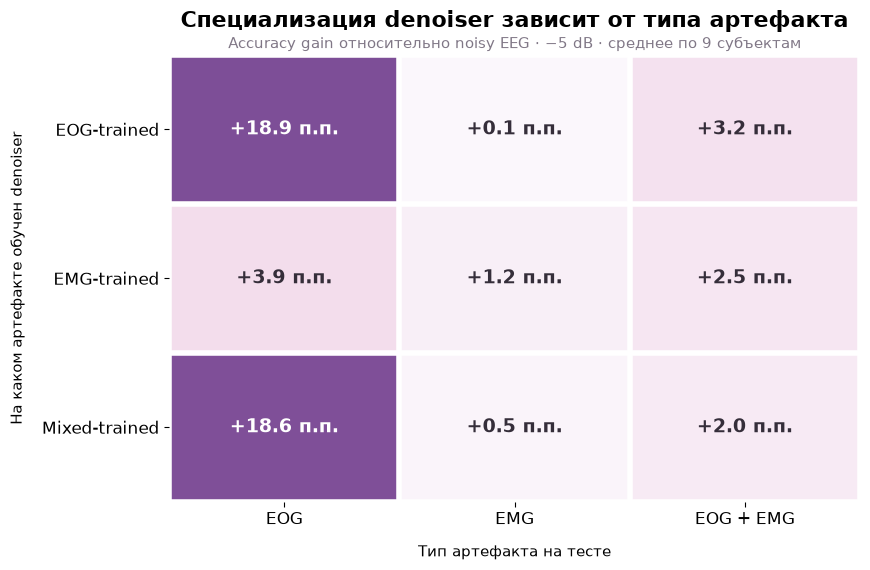

In [74]:
# ============================================================
# 51. PRETTY HEATMAP — ACCURACY GAIN VS RAW
# ============================================================

from matplotlib.colors import LinearSegmentedColormap

# наши результаты
plot_gain = gain_matrix.reindex(
    index=["EOG", "EMG", "MIXED"],
    columns=["EOG", "EMG", "EOG_EMG"]
).copy()

plot_gain.index = [
    "EOG-trained",
    "EMG-trained",
    "Mixed-trained"
]

plot_gain.columns = [
    "EOG",
    "EMG",
    "EOG + EMG"
]

arr = plot_gain.to_numpy(dtype=float)

# мягкая палитра: почти белый -> розовый -> фиолетовый
cmap = LinearSegmentedColormap.from_list(
    "pink_purple",
    [
        "#FBF7FC",
        "#F1D6E8",
        "#D89CC5",
        "#A96EB4",
        "#71458F"
    ]
)

fig, ax = plt.subplots(
    figsize=(8.8, 5.8)
)

im = ax.imshow(
    arr,
    cmap=cmap,
    aspect="auto",
    vmin=0,
    vmax=20
)

# подписи осей
ax.set_xticks(
    np.arange(arr.shape[1])
)

ax.set_xticklabels(
    plot_gain.columns,
    fontsize=12
)

ax.set_yticks(
    np.arange(arr.shape[0])
)

ax.set_yticklabels(
    plot_gain.index,
    fontsize=12
)

ax.set_xlabel(
    "Тип артефакта на тесте",
    fontsize=11,
    labelpad=12
)

ax.set_ylabel(
    "На каком артефакте обучен denoiser",
    fontsize=11,
    labelpad=12
)

# значения в ячейках
for i in range(arr.shape[0]):

    for j in range(arr.shape[1]):

        value = arr[i, j]

        text_color = (
            "white"
            if value > 10
            else "#352E3A"
        )

        ax.text(
            j,
            i,
            f"+{value:.1f} п.п.",
            ha="center",
            va="center",
            fontsize=14,
            fontweight="bold",
            color=text_color
        )

# тонкие белые разделители
ax.set_xticks(
    np.arange(-0.5, arr.shape[1], 1),
    minor=True
)

ax.set_yticks(
    np.arange(-0.5, arr.shape[0], 1),
    minor=True
)

ax.grid(
    which="minor",
    color="white",
    linewidth=4
)

ax.tick_params(
    which="minor",
    bottom=False,
    left=False
)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_title(
    "Специализация denoiser зависит от типа артефакта",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.text(
    0.5,
    1.015,
    "Accuracy gain относительно noisy EEG · −5 dB · среднее по 9 субъектам",
    transform=ax.transAxes,
    ha="center",
    fontsize=10.5,
    color="#807786"
)

plt.tight_layout()
plt.show()

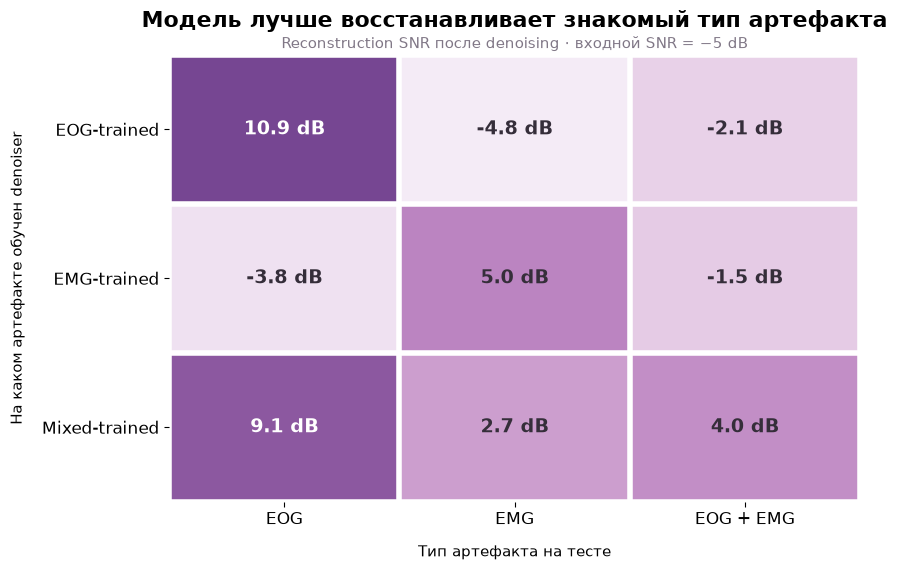

In [75]:
# ============================================================
# 52. PRETTY HEATMAP — RECONSTRUCTION SNR
# ============================================================

plot_snr = snr_matrix.reindex(
    index=["EOG", "EMG", "MIXED"],
    columns=["EOG", "EMG", "EOG_EMG"]
).copy()

plot_snr.index = [
    "EOG-trained",
    "EMG-trained",
    "Mixed-trained"
]

plot_snr.columns = [
    "EOG",
    "EMG",
    "EOG + EMG"
]

arr = plot_snr.to_numpy(dtype=float)

cmap = LinearSegmentedColormap.from_list(
    "snr_purple",
    [
        "#F5EDF7",
        "#DDBADD",
        "#B77CBD",
        "#754591"
    ]
)

fig, ax = plt.subplots(
    figsize=(8.8, 5.8)
)

im = ax.imshow(
    arr,
    cmap=cmap,
    aspect="auto",
    vmin=-5,
    vmax=11
)

ax.set_xticks(
    np.arange(arr.shape[1])
)

ax.set_xticklabels(
    plot_snr.columns,
    fontsize=12
)

ax.set_yticks(
    np.arange(arr.shape[0])
)

ax.set_yticklabels(
    plot_snr.index,
    fontsize=12
)

ax.set_xlabel(
    "Тип артефакта на тесте",
    fontsize=11,
    labelpad=12
)

ax.set_ylabel(
    "На каком артефакте обучен denoiser",
    fontsize=11,
    labelpad=12
)

for i in range(arr.shape[0]):

    for j in range(arr.shape[1]):

        value = arr[i, j]

        text_color = (
            "white"
            if value > 6
            else "#352E3A"
        )

        ax.text(
            j,
            i,
            f"{value:.1f} dB",
            ha="center",
            va="center",
            fontsize=14,
            fontweight="bold",
            color=text_color
        )

ax.set_xticks(
    np.arange(-0.5, arr.shape[1], 1),
    minor=True
)

ax.set_yticks(
    np.arange(-0.5, arr.shape[0], 1),
    minor=True
)

ax.grid(
    which="minor",
    color="white",
    linewidth=4
)

ax.tick_params(
    which="minor",
    bottom=False,
    left=False
)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_title(
    "Модель лучше восстанавливает знакомый тип артефакта",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.text(
    0.5,
    1.015,
    "Reconstruction SNR после denoising · входной SNR = −5 dB",
    transform=ax.transAxes,
    ha="center",
    fontsize=10.5,
    color="#807786"
)

plt.tight_layout()
plt.show()